# __Retail Sales Performance and Customer Value Analysis__

## __Introduction and Business Context__

### __Background__

In this day and age, technological knowledge and advancement have pushed many business owners to rely on data driven decisions rather than relying on their intuitions in understanding sales performance, optimising profitability, and improving customer relationships. The ability to analyse historical business sales transactions and customer purchasing behaviour informs organisations to identify revenue opportunities, boost business performance and develop plans and ideas that help sustain the growth of the business.
Successful businesses are not measured by the quantum of revenue generated alone but by understanding the factors that influence profitability, the effectiveness of promotional activities and the role played by different customer groups. It is also of great importance to identify valuable customers and know those whose purchasing engagement may be declining. 
This project takes a look at retail sales performance and customer value through a thorough analysis of transactional and customer level data. It combines sales performance analysis, profitability assessment and customer segmentation to generate actionable insights that can support strategic business decisions.

### __Problem Statement__

Most local retail businesses are faced with the challenges of identifying key drivers of sales and profitability, understanding the purchasing behaviour of their customers, and determining whether promotional strategies will deliver sustainable financial benefits.
In order for management to effectively track and identify underperforming product categories, underperforming regions and customer segments, recognise valuable customer segments, optimise discount strategies and implement effective customer retention campaigns there has to be a well structured approach in analysing the sales transactional data.



Retail businesses often face challenges in identifying the key drivers of sales and profitability, understanding differences in customer purchasing behaviour and determining whether promotional strategies deliver sustainable financial benefits.

Without a structured approach to analysing sales and customer data, management may struggle to identify underperforming product categories, recognise valuable customer segments, optimise discount strategies and implement effective customer retention initiatives.
This project analyses retail sales performance and customer purchasing behaviour using historical transactional retail data. The analysis focuses on sales trends, top-performing products in terms of revenue, top-performing regions with regard to revenue, and identifying the purchasing patterns of customers to help the business grow revenue while protecting profit and retaining valuable customers. The findings aim to provide recommendations that could improve customer engagement, increase customer lifetime value, and increase the profitability of the business. This project makes use of analytical tools such as Python for data cleaning and preparation, exploratory data analysis and visualisation, SQL for performing the sales and segmentation analysis, and then Tableau for interactive business reporting dashboards.

### __Project Objective__

The goal of this project is to analyse retail sales performance and to demonstrate how data-driven decision-making can help retail businesses strengthen customer relationships to boost the financial performance of the business entity. 

### __Business Questions__

1. Which product categories generate the most revenue and profit?

2. Which months or quarters perform best?

3. Which customer segment or region contributes the most revenue and profit? And how do revenue, profit, and average order value (AOV) differ by customer segment? 

4. How are discounts associated with sales, profit, and profit margin? Which discounts are effective at increasing sales without destroying profitability?

5. How can customers be segmented using Recency, Frequency, and Monetary (RFM) value? And which customers can be classified as "Champions","Loyal","Potential Loyalist","At Risk","Hibernating", or "Lost"?


### __Dataset Description__

The dataset is a synthetic one generated by ChatGPT and made up of 60,000 rows of sales transaction data and 17 different retail sales variables of interest comprising the following:

* __OrderID:__ Unique order identification of items	

* __OrderDate:__ The date the order was made	

* __CustomerID:__ Unique customer identification	

* __CustomerName:__ Names of customers	

* __CustomerSegment:__ Category of customer	

* __Product:__ Items being purchased

* __Category:__ Category of product purchased	

* __Region:__ Location of customers	

* __Quantity:__ Number of items purchased	

* __Sales:__ Prices of items purchased	

* __Discount:__ Discount on each item	

* __Profit:__ Profit made on each item	

* __ShipMode:__ The type of shipment used for each item	

* __PaymentMethod:__ Mode of payment used to purchase the item	

* __SignupDate:__ Customer subscription date	


## __Importing the necessary libraries__

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings
warnings.filterwarnings('ignore')

# Aesthetic settings
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
%matplotlib inline

## __Data Preparation__

In [2]:
# Loading and inspection of dataset

df=pd.read_excel("C:/Users/Administrator/Desktop/Data_Analyst_Toolkit/Retail_Sales_Customer_Churn_Dashboard/Retail_Sales_Customer_Data.xlsx")

print("========= First Five Rows Of Dataset ===========")
df.head()

========= First Five Rows Of Dataset ===========


,OrderID,OrderDate,CustomerID,CustomerName,CustomerSegment,Product,Category,Region,Quantity,Sales,Discount,Profit,ShipMode,PaymentMethod,SignupDate
0,ORD-026309,2023-10-09 00:00:00,CUST-03755,Abena Appiah,Consumer,sticky notes,Office Supplies,NORTH,10.0,1394.20,0.30,206.17,Economy,BANK TRANSFER,2022-03-08 00:00:00
1,ORD-052513,2024-06-22 00:00:00,CUST-07174,James Nwosu,small business,shampoo,beauty & personal care,central,1.0,352.14,0.25,7.81,Economy,MOBILE MONEY,2023-01-02 00:00:00
2,ORD-050062,2022-09-19 00:00:00,CUST-06204,Ama Boateng,Consumer,Notebook,Office Supplies,North,3.0,1113.09,0.00,181.77,Economy,MOBILE MONEY,2020-10-25 00:00:00
3,ORD-045394,2023-07-26 00:00:00,CUST-02891,Abena Owusu,Corporate,printer paper,Office Supplies,South,2.0,921.62,0.00,401.35,SAME DAY,bank transfer,2020-07-11 00:00:00
4,ORD-017260,2022-06-11 00:00:00,CUST-08642,Amaka Eze,corporate,Leather Belt,APPAREL,EAST,5.0,593.15,0.30,33.26,Express,NaN,2020-06-20 00:00:00


In [3]:
print("========= Tail End of Dataset ===========")
df.tail()

========= Tail End of Dataset ===========


,OrderID,OrderDate,CustomerID,CustomerName,CustomerSegment,Product,Category,Region,Quantity,Sales,Discount,Profit,ShipMode,PaymentMethod,SignupDate
59995,ORD-033635,2023-06-23 00:00:00,CUST-07789,Abena Addo,Small Business,winter jacket,Apparel,Central,5.0,2498.75,0.20,281.64,Standard,MOBILE MONEY,2019-04-19 00:00:00
59996,ORD-056849,2024-08-18 00:00:00,CUST-03864,Kwame Williams,CONSUMER,MEN'S T-SHIRT,APPAREL,North,10.0,842.30,0.15,70.10,Economy,Cash,13/06/19
59997,ORD-032843,14/02/22,CUST-07796,John Danso,small business,Wool Sweater,apparel,South,7.0,1729.56,0.00,668.70,economy,paypal,2020-12-11 00:00:00
59998,ORD-047281,30-06-2023,CUST-04634,Chioma Danso,Small Business,USB-C CHARGER,ELECTRONICS,east,2.0,35.80,0.00,8.97,Same Day,Mobile Money,2021-04-11 00:00:00
59999,ORD-033107,2024-11-27 00:00:00,CUST-06166,Yaw Brown,Consumer,wool sweater,Apparel,east,1.0,333.84,0.15,77.60,Standard,BANK TRANSFER,2019-05-01 00:00:00


In [4]:
# Data Information

print("========= Data Information ===========")
df.info()

========= Data Information ===========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          60000 non-null  object 
 1   OrderDate        60000 non-null  object 
 2   CustomerID       60000 non-null  object 
 3   CustomerName     58800 non-null  object 
 4   CustomerSegment  60000 non-null  object 
 5   Product          59400 non-null  object 
 6   Category         60000 non-null  object 
 7   Region           59100 non-null  object 
 8   Quantity         59400 non-null  float64
 9   Sales            58800 non-null  float64
 10  Discount         57600 non-null  float64
 11  Profit           58200 non-null  float64
 12  ShipMode         58200 non-null  object 
 13  PaymentMethod    58500 non-null  object 
 14  SignupDate       60000 non-null  object 
dtypes: float64(4), object(11)
memory usage: 6.9+ MB


In [5]:
# Checking For Missing Entries

print("========= Missing Entries ===========")
df.isnull().sum()

========= Missing Entries ===========


OrderID               0
OrderDate             0
CustomerID            0
CustomerName       1200
CustomerSegment       0
Product             600
Category              0
Region              900
Quantity            600
Sales              1200
Discount           2400
Profit             1800
ShipMode           1800
PaymentMethod      1500
SignupDate            0
dtype: int64

In [6]:
# Data Description

print("\n" + "="*50)
print("Statistical Summary Of Dataset")
print("="*50)

print(df.describe())

print("\nCategorical columns value counts:")

categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))  # top 10 most frequent


Statistical Summary Of Dataset
           Quantity         Sales      Discount        Profit
count  59400.000000  58800.000000  57600.000000  58200.000000
mean       5.493788   1380.663952      0.117137    287.460147
std        2.868252   1141.417224      0.108012    355.494012
min        1.000000      5.060000      0.000000   -675.580000
25%        3.000000    438.862500      0.000000     45.700000
50%        5.000000   1057.020000      0.100000    168.175000
75%        8.000000   2072.182500      0.200000    422.430000
max       10.000000   4999.900000      0.300000   2446.260000

Categorical columns value counts:

OrderID:
OrderID
ORD-052523    3
ORD-044062    3
ORD-001717    3
ORD-052150    3
ORD-026833    3
ORD-025567    3
ORD-047379    3
ORD-019002    3
ORD-045565    3
ORD-042852    3
Name: count, dtype: int64

OrderDate:
OrderDate
2024-02-07 00:00:00    98
2024-05-06 00:00:00    92
2024-05-07 00:00:00    92
2024-05-05 00:00:00    86
2024-07-05 00:00:00    86
2024-04-03 00:00:00

### __Data Cleaning And Transformation__

In [7]:
# Checking For Duplicated Entries

print("========= Duplicated Entries ===========")
df.duplicated().sum()

========= Duplicated Entries ===========


np.int64(1052)

In [8]:
# Removing Duplicates

df = df.drop_duplicates()

In [9]:
# Removing incomplete records required for analysis

df = df.dropna(subset=["CustomerID","CustomerName","OrderID","Product",
                       "OrderDate","Region"])

# For Categorical Columns
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna('N.A')

# For Numerical Columns
num_cols = df.select_dtypes(include=["number"]).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [10]:
# Standardising Text Cases

for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

In [11]:
# Standardising The Order Date column

df['OrderDate'] = pd.to_datetime(df['OrderDate'], format = 'mixed', dayfirst= True ,errors='coerce')
df['OrderDate'] = df['OrderDate'].dt.strftime('%Y-%m-%d')
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors = 'coerce')

In [12]:
# Standardizing The Signed up Data Column

df['SignupDate'] = pd.to_datetime(df['SignupDate'],format = 'mixed',dayfirst= True,errors="coerce")
df['SignupDate'] = df['SignupDate'].dt.strftime('%Y-%m-%d')
df['SignupDate'] = pd.to_datetime(df['SignupDate'], errors = 'coerce')   

In [13]:
# Creating The Tenure Column

df['start_date'] = pd.to_datetime(df['SignupDate'])
today = pd.Timestamp.today().normalize()

df['tenure_days'] = (today - df['start_date']).dt.days
df['Tenure_years'] = (df['tenure_days']/365.25).round(0)


In [14]:
# Renaming Of Columns

df.rename(columns={'OrderID':'Order_ID','OrderDate':'Order_Date','CustomerName':'Customer_Name','CustomerID':'Customer_ID','CustomerSegment':'Customer_Segment','ShipMode':'Shipment_Mode',
                  'PaymentMethod':'Payment_Method','ChurnReason':'Churn_Reason'},inplace=True)
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name',
       'Customer_Segment', 'Product', 'Category', 'Region', 'Quantity',
       'Sales', 'Discount', 'Profit', 'Shipment_Mode', 'Payment_Method',
       'SignupDate', 'start_date', 'tenure_days', 'Tenure_years'],
      dtype='object')

In [15]:
# Validate Data Types

print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 56282 entries, 0 to 59999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          56282 non-null  object        
 1   Order_Date        56282 non-null  datetime64[ns]
 2   Customer_ID       56282 non-null  object        
 3   Customer_Name     56282 non-null  object        
 4   Customer_Segment  56282 non-null  object        
 5   Product           56282 non-null  object        
 6   Category          56282 non-null  object        
 7   Region            56282 non-null  object        
 8   Quantity          56282 non-null  float64       
 9   Sales             56282 non-null  float64       
 10  Discount          56282 non-null  float64       
 11  Profit            56282 non-null  float64       
 12  Shipment_Mode     56282 non-null  object        
 13  Payment_Method    56282 non-null  object        
 14  SignupDate        56282 non

In [16]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Customer_Segment,Product,Category,Region,Quantity,Sales,Discount,Profit,Shipment_Mode,Payment_Method,SignupDate,start_date,tenure_days,Tenure_years
0,Ord-026309,2023-10-09,Cust-03755,Abena Appiah,Consumer,Sticky Notes,Office Supplies,North,10.0,1394.20,0.30,206.17,Economy,Bank Transfer,2022-03-08,2022-03-08,1721,5.0
1,Ord-052513,2024-06-22,Cust-07174,James Nwosu,Small Business,Shampoo,Beauty & Personal Care,Central,1.0,352.14,0.25,7.81,Economy,Mobile Money,2023-01-02,2023-01-02,1421,4.0
2,Ord-050062,2022-09-19,Cust-06204,Ama Boateng,Consumer,Notebook,Office Supplies,North,3.0,1113.09,0.00,181.77,Economy,Mobile Money,2020-10-25,2020-10-25,2220,6.0
3,Ord-045394,2023-07-26,Cust-02891,Abena Owusu,Corporate,Printer Paper,Office Supplies,South,2.0,921.62,0.00,401.35,Same Day,Bank Transfer,2020-07-11,2020-07-11,2326,6.0
4,Ord-017260,2022-06-11,Cust-08642,Amaka Eze,Corporate,Leather Belt,Apparel,East,5.0,593.15,0.30,33.26,Express,N.A,2020-06-20,2020-06-20,2347,6.0


In [17]:
# Standardising Column Names

# Strip whitespace 
df.columns = [col.strip() for col in df.columns]

# Title Casing
df.columns = [col.title() for col in df.columns]

print("Final columns:", df.columns.tolist())
df.head()

Final columns: ['Order_Id', 'Order_Date', 'Customer_Id', 'Customer_Name', 'Customer_Segment', 'Product', 'Category', 'Region', 'Quantity', 'Sales', 'Discount', 'Profit', 'Shipment_Mode', 'Payment_Method', 'Signupdate', 'Start_Date', 'Tenure_Days', 'Tenure_Years']


,Order_Id,Order_Date,Customer_Id,Customer_Name,Customer_Segment,Product,Category,Region,Quantity,Sales,Discount,Profit,Shipment_Mode,Payment_Method,Signupdate,Start_Date,Tenure_Days,Tenure_Years
0,Ord-026309,2023-10-09,Cust-03755,Abena Appiah,Consumer,Sticky Notes,Office Supplies,North,10.0,1394.20,0.30,206.17,Economy,Bank Transfer,2022-03-08,2022-03-08,1721,5.0
1,Ord-052513,2024-06-22,Cust-07174,James Nwosu,Small Business,Shampoo,Beauty & Personal Care,Central,1.0,352.14,0.25,7.81,Economy,Mobile Money,2023-01-02,2023-01-02,1421,4.0
2,Ord-050062,2022-09-19,Cust-06204,Ama Boateng,Consumer,Notebook,Office Supplies,North,3.0,1113.09,0.00,181.77,Economy,Mobile Money,2020-10-25,2020-10-25,2220,6.0
3,Ord-045394,2023-07-26,Cust-02891,Abena Owusu,Corporate,Printer Paper,Office Supplies,South,2.0,921.62,0.00,401.35,Same Day,Bank Transfer,2020-07-11,2020-07-11,2326,6.0
4,Ord-017260,2022-06-11,Cust-08642,Amaka Eze,Corporate,Leather Belt,Apparel,East,5.0,593.15,0.30,33.26,Express,N.A,2020-06-20,2020-06-20,2347,6.0


In [18]:
# Detecting and getting rid of outliers

numeric_cols = df.select_dtypes(include = "number").columns

Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR


# Removing outliers
df_clean = df[~((df[numeric_cols]<lower_bound)|(df[numeric_cols]>upper_bound)).any(axis=1)]

print("Before:",df.shape)
print("After:",df_clean.shape)



Before: (56282, 18)
After: (52593, 18)


In [19]:
# Final Quality Check

print(df_clean.isnull().sum())

print(df_clean.duplicated().sum())

Order_Id            0
Order_Date          0
Customer_Id         0
Customer_Name       0
Customer_Segment    0
Product             0
Category            0
Region              0
Quantity            0
Sales               0
Discount            0
Profit              0
Shipment_Mode       0
Payment_Method      0
Signupdate          0
Start_Date          0
Tenure_Days         0
Tenure_Years        0
dtype: int64
5


In [20]:
# Saving Cleaned dataset

df_clean.to_csv('Cleaned_Retail_Sales_Customer_Analytics.csv',index=False)



## __Analysis__

### __Creation of a Database__

In [21]:
# Creating a Local SQLite database
conn = sqlite3.connect("retail_analytics.db")

# Writing the Dateframe into a database table
df_clean.to_sql("retail_sales",conn,if_exists="replace",index=False)

print("Retail data loaded into SQLite.")


Retail data loaded into SQLite.


### __Exploratory Data Analysis__

In [22]:
# Deleting Columns irrelevant To The Exploratory Data Analysis

df1=df_clean.drop(['Order_Id','Order_Date','Customer_Id','Customer_Name','Signupdate','Start_Date','Tenure_Days'],axis=1)

df1.head()

,Customer_Segment,Product,Category,Region,Quantity,Sales,Discount,Profit,Shipment_Mode,Payment_Method,Tenure_Years
0,Consumer,Sticky Notes,Office Supplies,North,10.0,1394.20,0.30,206.17,Economy,Bank Transfer,5.0
1,Small Business,Shampoo,Beauty & Personal Care,Central,1.0,352.14,0.25,7.81,Economy,Mobile Money,4.0
2,Consumer,Notebook,Office Supplies,North,3.0,1113.09,0.00,181.77,Economy,Mobile Money,6.0
3,Corporate,Printer Paper,Office Supplies,South,2.0,921.62,0.00,401.35,Same Day,Bank Transfer,6.0
4,Corporate,Leather Belt,Apparel,East,5.0,593.15,0.30,33.26,Express,N.A,6.0


In [23]:
# Separating Categorical and Numeric Variables

categorical_cols=df1.select_dtypes(include= 'object').columns
numeric_cols = df1.select_dtypes(include=np.number).columns.tolist()

print("\n" + "="*50)
print("Categorical Variables:")
print("="*50)
print(categorical_cols)

print("\n" + "="*50)
print("Numerical Variables:")
print("="*50)
print(numeric_cols)


Categorical Variables:
Index(['Customer_Segment', 'Product', 'Category', 'Region', 'Shipment_Mode',
       'Payment_Method'],
      dtype='object')

Numerical Variables:
['Quantity', 'Sales', 'Discount', 'Profit', 'Tenure_Years']


Quantity
Skew : 0.1


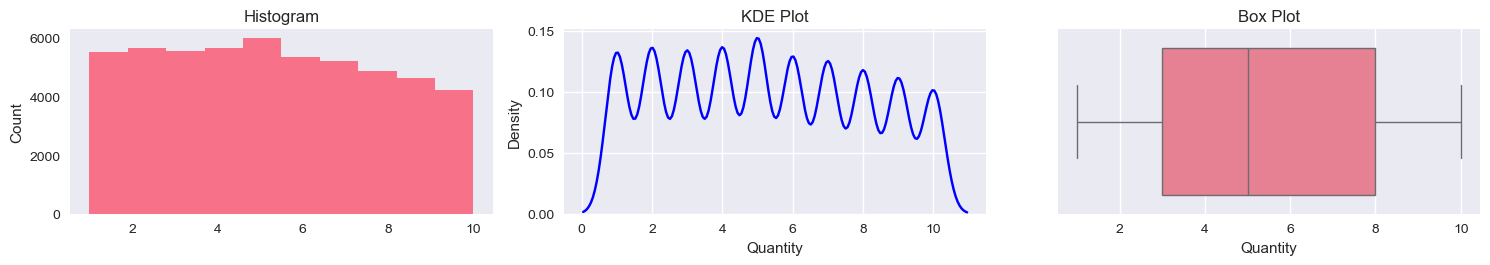

Sales
Skew : 0.97


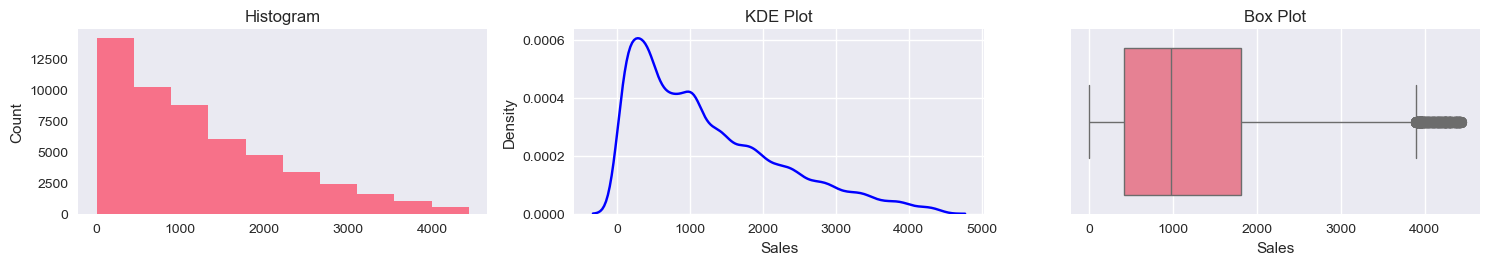

Discount
Skew : 0.31


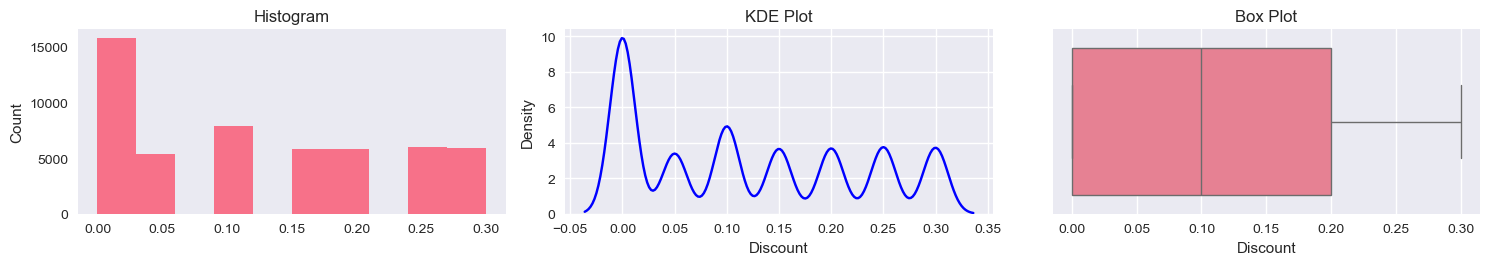

Profit
Skew : 0.97


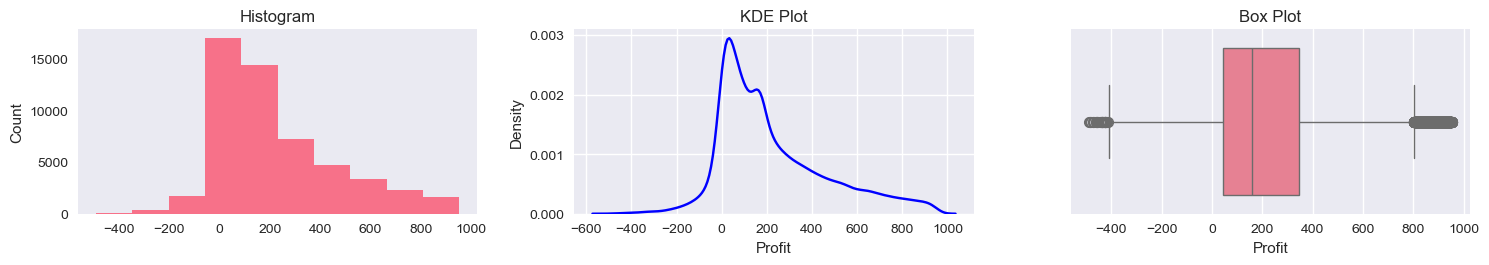

In [24]:
# Univariate Analysis

for col in num_cols:
    print(col)
    print('Skew :', round(df1[col].skew(), 2))

    fig=plt.figure(figsize=(15,3))
    
    # Histogram
    plt.subplot(1, 3, 1)  # Changed to 1 row and 3 columns
    df1[col].hist(grid=False)
    plt.ylabel('Count')
    plt.title('Histogram')
    
    # KDE Plot
    plt.subplot(1, 3, 2)  # Second subplot for KDE
    sns.kdeplot(df1[col], color='blue')
    plt.title('KDE Plot')
    
    # Box Plot
    plt.subplot(1, 3, 3)  # Third subplot for Box Plot
    sns.boxplot(x=df1[col])
    plt.title('Box Plot')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjusting layout for better spacing
    plt.show()

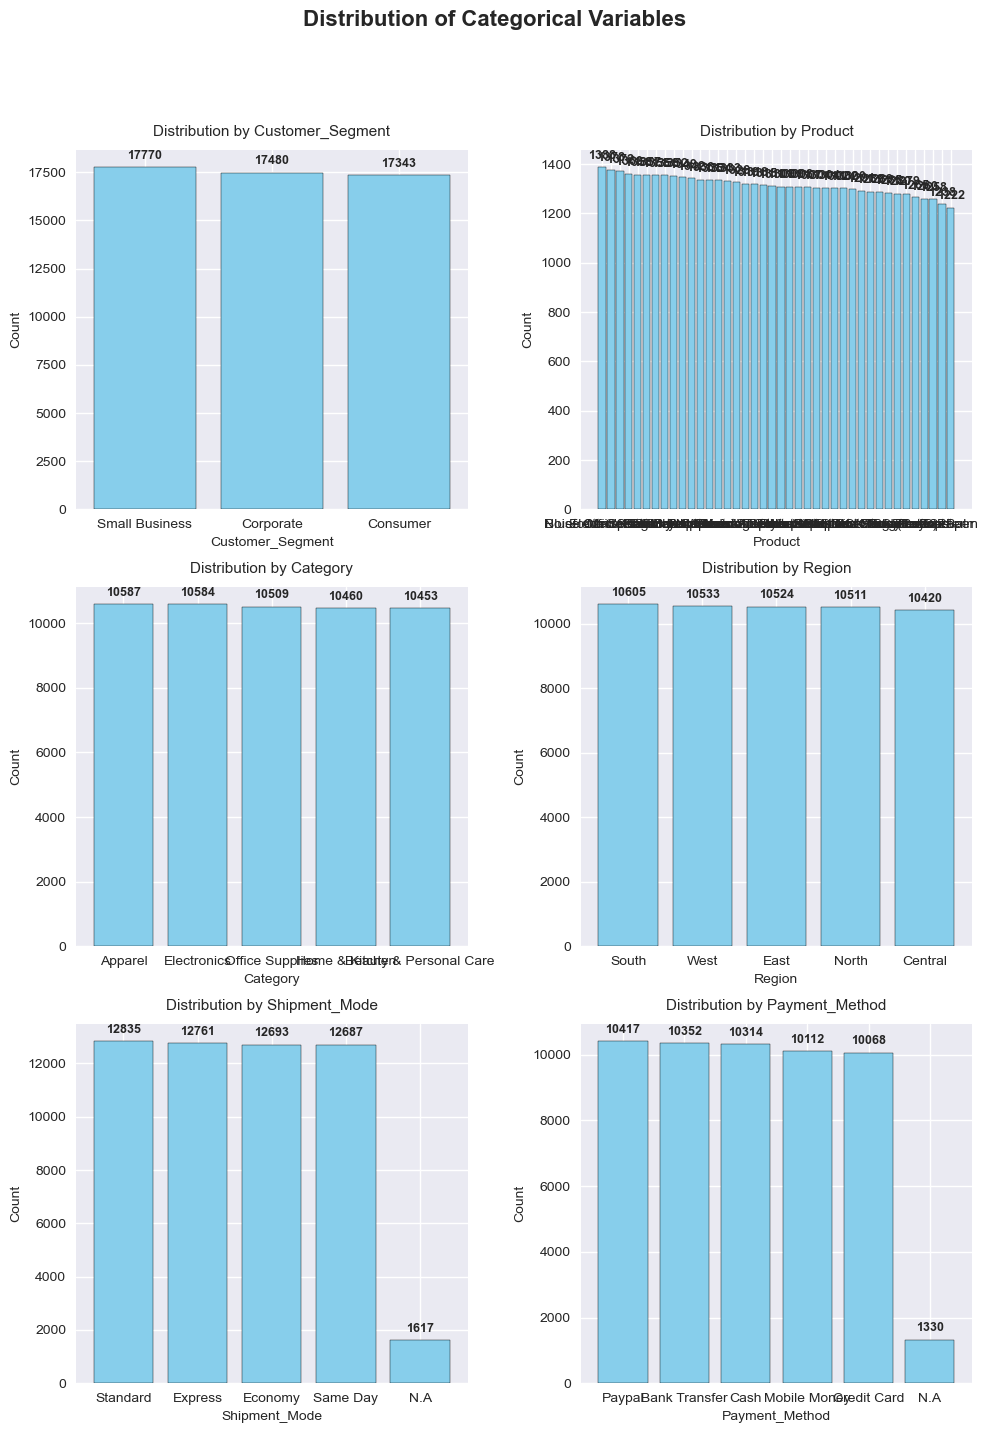

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(10, 14))
axes = axes.flatten()           # convert 2D array to 1D for easy indexing

# Main title
fig.suptitle('Distribution of Categorical Variables', 
             fontsize=16, fontweight='bold', y=1.02)

# Plot bar charts
for i, col in enumerate(categorical_cols):
    counts = df1[col].value_counts()
    
    bars = axes[i].bar(counts.index, counts.values, color='skyblue', edgecolor='black')
    
    axes[i].set_title(f'Distribution by {col}', fontsize=11, pad=10)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)
    
    # Data labels 
    axes[i].bar_label(bars, padding=4, fontsize=9, fontweight='bold')

     # Rotate x-ticks if labels are long
    axes[i].tick_params(axis='x', rotation=45 if col == 'Geography' else 0)

# Adjusting  layout
plt.tight_layout()
plt.subplots_adjust(top=0.92)   

plt.show()

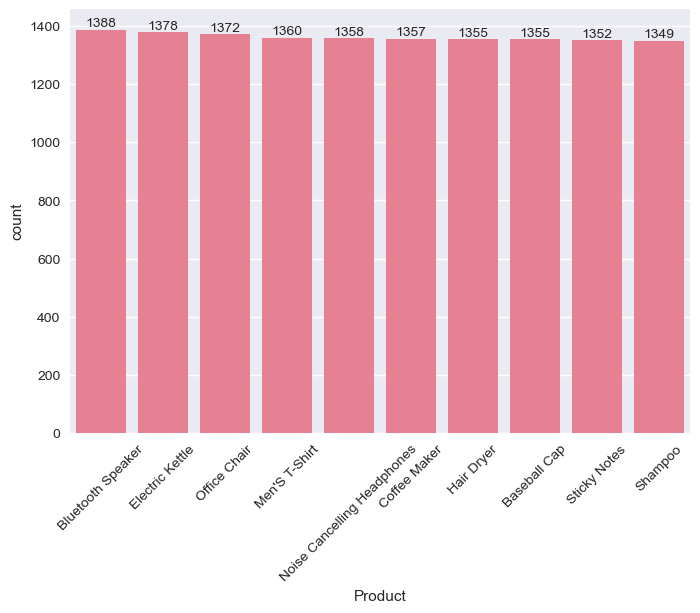

In [26]:
# For Products, we consider top 10

top10 = df1['Product'].value_counts().head(10).index

ax = sns.countplot(data=df1, x = 'Product', order = top10)

for container in ax.containers:
    ax.bar_label(container)
plt.xticks(rotation = 45)
plt.show()

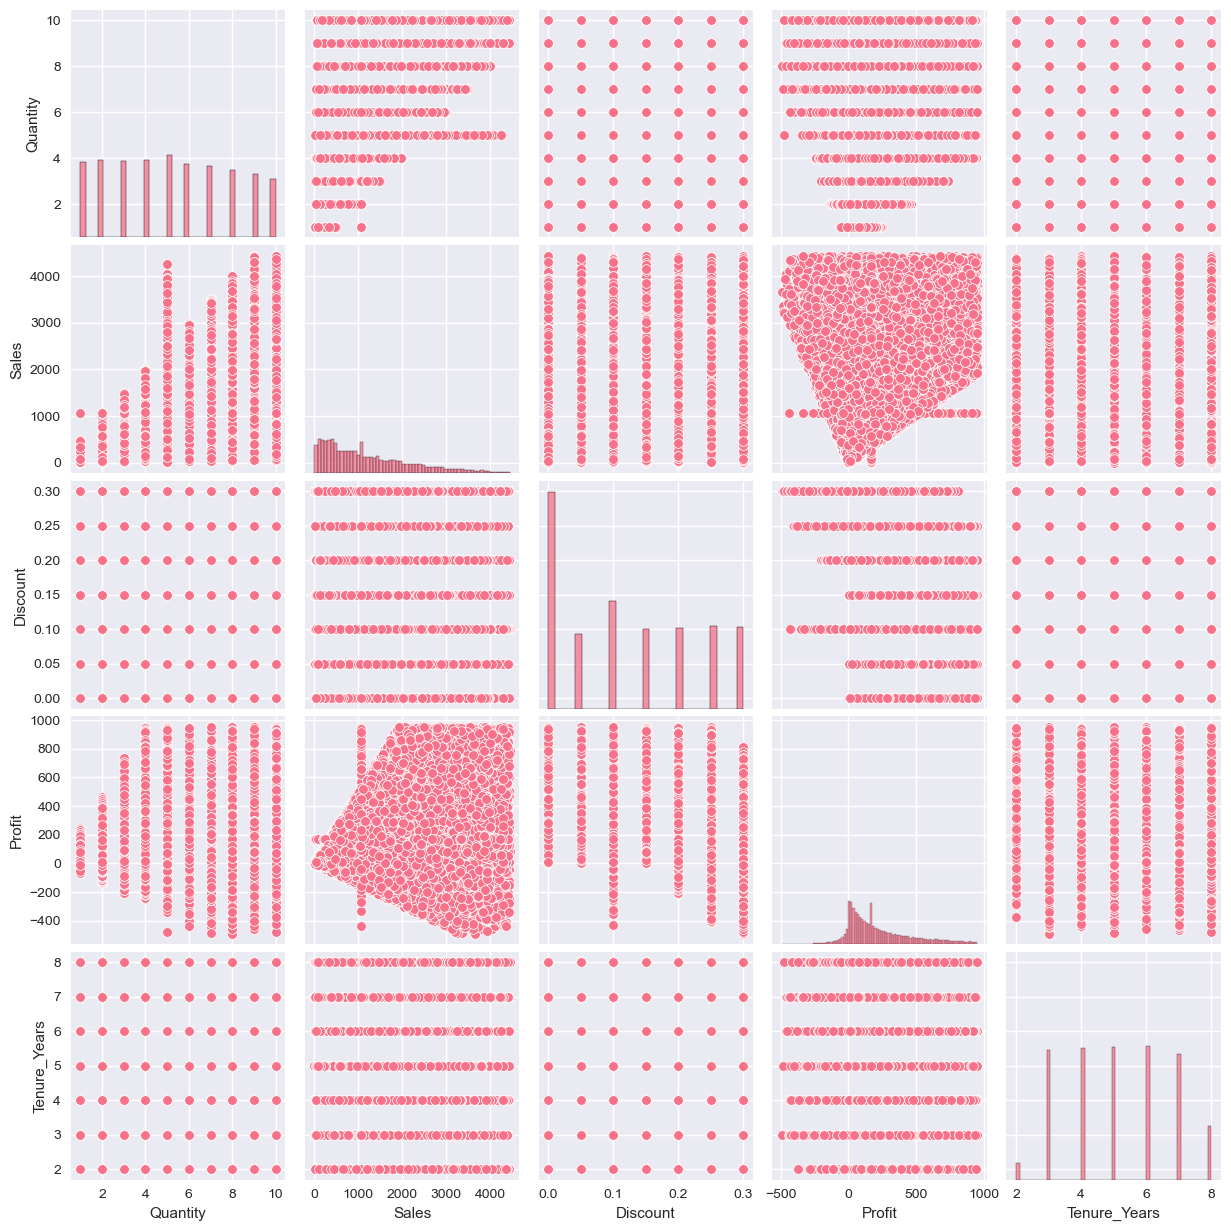

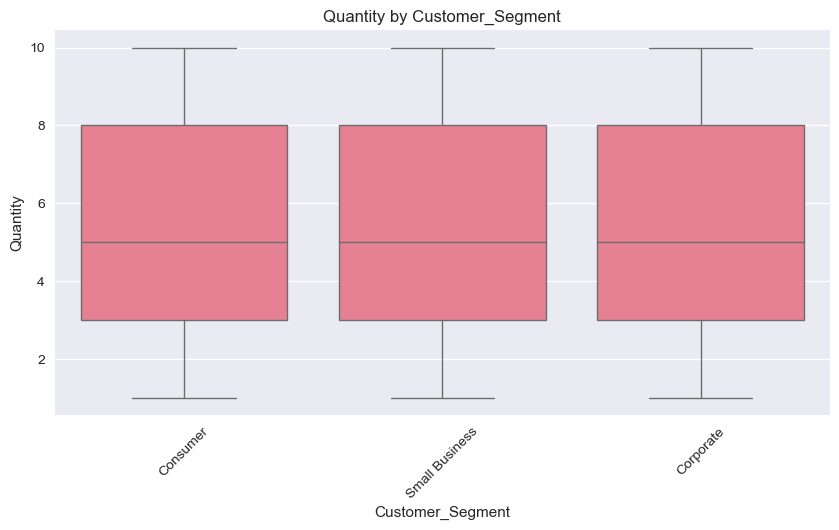

In [27]:
# Bivariate Analysis

if len(numeric_cols) >= 2:
    sns.pairplot(df1[numeric_cols])
    plt.show()

# categorical vs numeric
if len(categorical_cols) > 0 and len(numeric_cols) > 0:
    cat_col = categorical_cols[0]
    num_col = numeric_cols[0]

    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df1, x=cat_col, y=num_col)
    plt.title(f"{num_col} by {cat_col}")
    plt.xticks(rotation=45)
    plt.show()

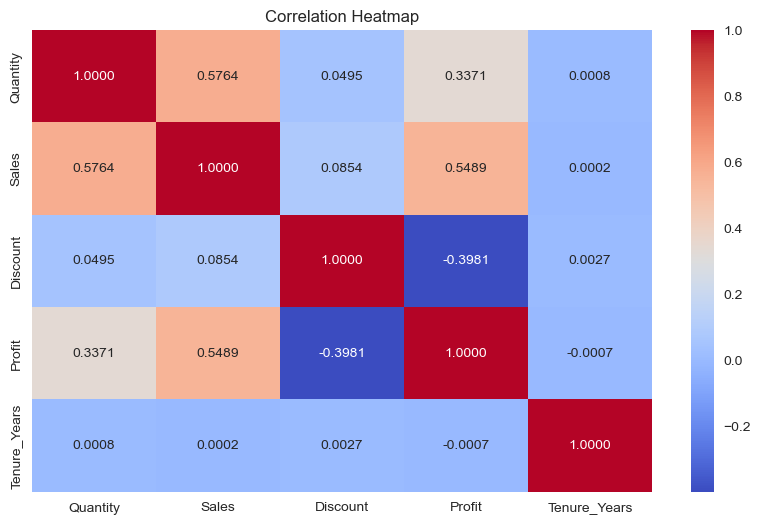

In [28]:
# Correlation Analysis

if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 6))
    sns.heatmap(df1[numeric_cols].corr(),annot=True,cmap="coolwarm",fmt=".4f")
    plt.title("Correlation Heatmap")
    plt.show()

__Insight From EDA__

1. The dataset was initially made up of 60,000 rows and 15 columns, making up 15 features. After data cleaning, where duplicates and some null entries as well as outliers were gotten rid of, the row number reduced to 52,593 with an increment of 3 more columns due to computation of the 'Tenure_years' column.

2. Initially the dataset was made up of variables of data type 'float64' and 'object', but after the data cleaning, the overall data types changed to 'datetime64', 'float64','int64', and 'object'.

3. The dataset had missing values in the 'Customer_Name', 'Region', 'Product', 'Quantity', 'Sales', 'Discount','Profit','Ship_Mode', and 'Payment_Method' columns. Aside from the missing values from the 'Region' and 'Product' columns that were expunged due to their importance, the other missing values from the other categorical variables were replaced by 'N.A'. The missing values from the numeric variables where estimated using the median values of each column.
4. The following are the distributions of variables:

* __Quantity:__ With a mean of approximately 5.5, a standard deviation of approximately 2.9, and a skewness metric of 0.01, it suggests that the data distribution is essentially symmetric since there is no meaningful skew.
* __Sales_revenue:__ The data distribution of this variable is that of a positive right-skewed one, though not extreme. A mean of approximately ₵1,380.7, a standard deviation of ₵1,141.4, and a skewness metric of 0.97 is indicative of the nature of the data distribution.
* __Discount:__ This variable has a positive skewness of 0.38, a mean of approximately 0.117 (11.7%), and a standard deviation of 0.108 (10.8%), suggesting that the data distribution is approximately symmetric too.
* __Profit:__ A skewness of 1.76 exhibits strong positive skewness, indicating a data distribution that has most observations being concentrated at lower values, while a smaller number of unusually high values create a long right tail.
* __Customer_Segments:__ There is a fairly even distribution of customers between the 3 (small businesses, corporate, and consumer) segments with marginal differences.
* __Products:__ The distribution of the number of products with regard to the top 10 is also fairly evenly distributed, with marginal differences shown.
* __Category:__ The distribution of the product category is fairly even with marginal differences between the various categories.
* __Regions:__ Again, the number of customers distributed across the various regions is fairly distributed with very little in terms of numbers to separate them.

5. With regard to correlation, the following holds:
* There is a moderate positive correlation between quantity and sales revenue, meaning that an increase in any of these two variables would cause an increase in the other, though the relationship is not extremely strong.
* There is a weak positive correlation between quantity and profit, which suggests that there is a slight upward relationship between the variables, though not strong.
* The correlation between quantity and tenure is negligible, and the same can be said about quantity and discount.
* Sales correlates moderately but positively with quantity and profits but has a negligible relationship with discount and tenure.
* Discount has a weak to moderate negative correlation with profit but a negligible correlation with other variables.
* Tenure has a negligible correlation with all the other variables.

### __Answers To Business Questions__

#### __1. Which product categories generate the most revenue and profit?__

In [29]:
# Using SQL queries from retail_sales table( retail_analytics database)

query = """
SELECT 
Category, 
SUM(Sales) AS Total_sales,SUM(Profit) AS Total_profit
FROM retail_sales
GROUP BY Category
ORDER BY Total_profit DESC 
"""
Product_category_summary = pd.read_sql_query(query,conn)
display(Product_category_summary)

,Category,Total_sales,Total_profit
0,Electronics,13016584.49,2357252.12
1,Apparel,12987134.35,2343026.02
2,Home & Kitchen,12762641.25,2321346.70
3,Office Supplies,12928930.98,2303141.56
4,Beauty & Personal Care,12724941.79,2296567.10


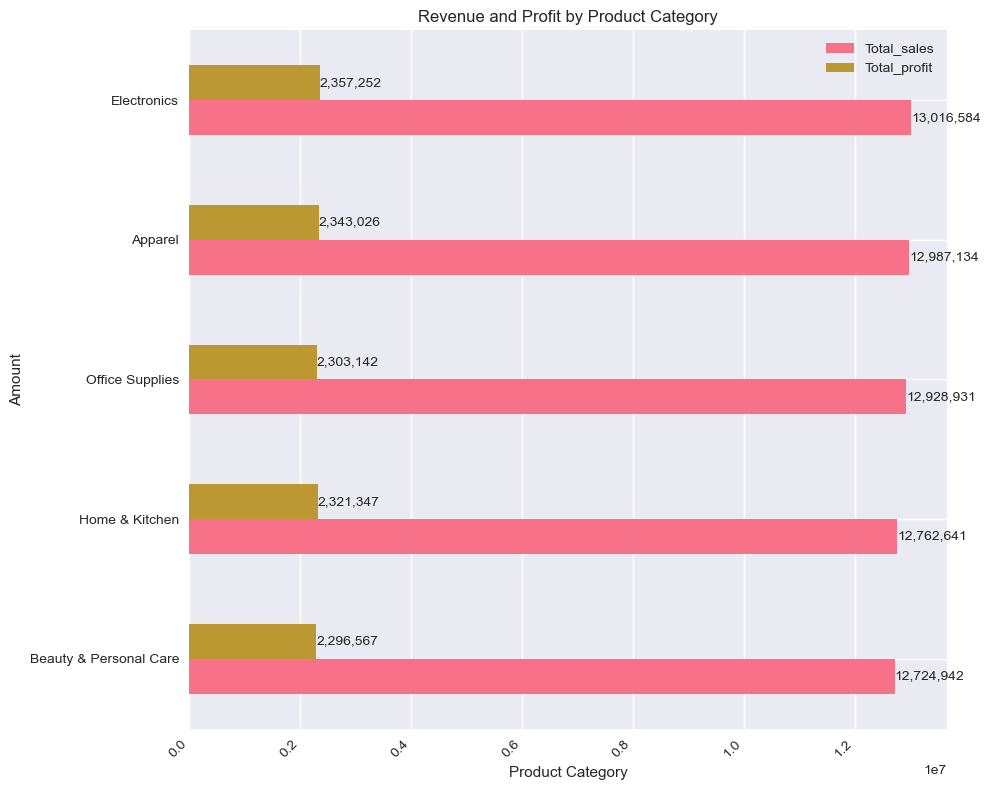

In [30]:
# Visualize the SQL output
ax = Product_category_summary.sort_values("Total_sales").plot(x="Category",y=["Total_sales","Total_profit"],kind="barh",figsize=(10,8))

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.0f}')
plt.title("Revenue and Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

__Findings__

* Electronics generated the highest total sales revenue of ₵13,016,584.49 as well as the highest total profit of ₵2,357,252.12 of all the product categories.
* The profits generated by the other product categories are evenly distributed, with electronics marginally exceeding that of the other categories.
* Though office supplies generated more sales revenue than home and kitchen supplies, they generated less profit. 

__Insight__

* The electronics category of products is the strongest for generating the most sales and profit, but the other categories are not necessarily behind with regard to sales performance considering the marginal difference of the total profits.


#### __2. Which months or quarters perform best?__

In [31]:
# Analyzing monthly performance 

query = """
SELECT strftime('%Y-%m',Order_date) AS sales_month,   
ROUND(SUM(Sales),2) AS Total_sales,            
ROUND(SUM(Profit),2) AS Total_profit,          
COUNT(DISTINCT Order_id) AS Total_orders,       
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS Profit_margin_pct   
FROM retail_sales 
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y-%m',Order_date);   
"""
Monthly_perf = pd.read_sql_query(query,conn)
display(Monthly_perf)

,sales_month,Total_sales,Total_profit,Total_orders,Profit_margin_pct
0,2022-01,1067882.16,180989.90,861,16.95
1,2022-02,946195.68,169249.45,809,17.89
2,2022-03,1101771.52,210932.73,886,19.14
3,2022-04,1163339.04,209832.23,987,18.04
4,2022-05,1203414.25,207191.46,992,17.22
5,2022-06,1260316.20,227072.95,1026,18.02
6,2022-07,1328551.27,236824.05,1077,17.83
7,2022-08,1417608.07,255621.56,1148,18.03
8,2022-09,1355947.97,246316.62,1100,18.17
9,2022-10,1490302.63,259346.63,1229,17.40


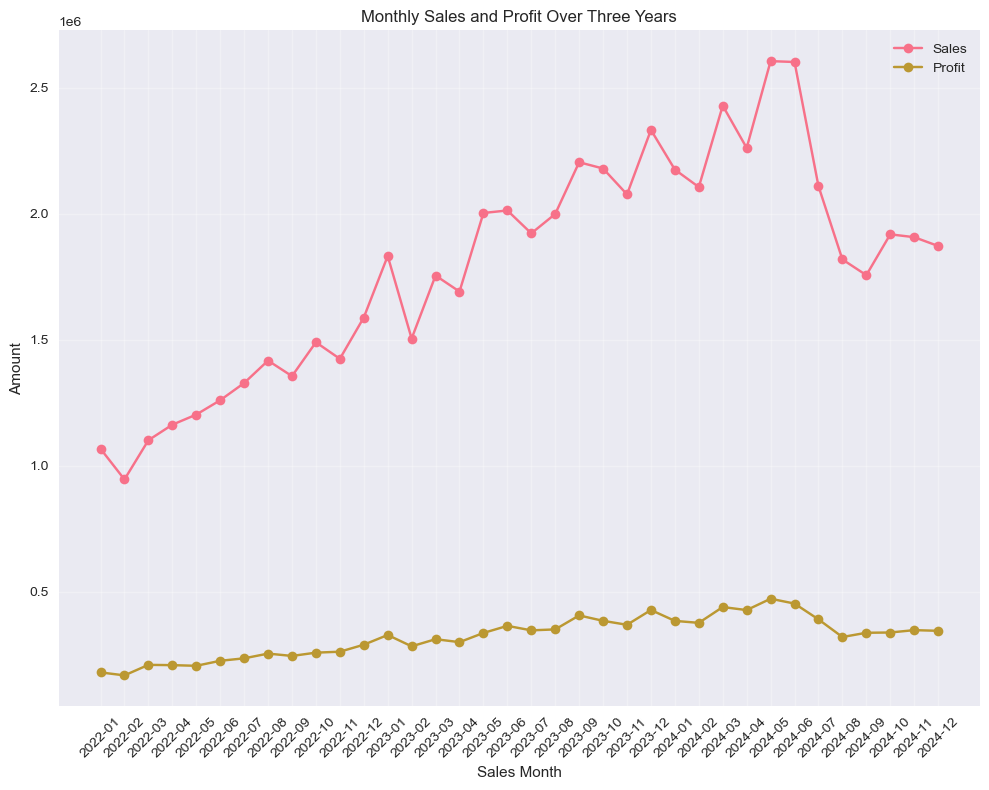

In [32]:
# Monthly Trend Chart To Identify Growth, Declines, Seasonality, and Unusual Monthly Performance.

plt.figure(figsize=(10, 8))

plt.plot(Monthly_perf["sales_month"],Monthly_perf["Total_sales"],marker="o",label="Sales")
plt.plot(Monthly_perf["sales_month"],Monthly_perf["Total_profit"],marker="o",label="Profit")

plt.title("Monthly Sales and Profit Over Three Years")
plt.xlabel("Sales Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

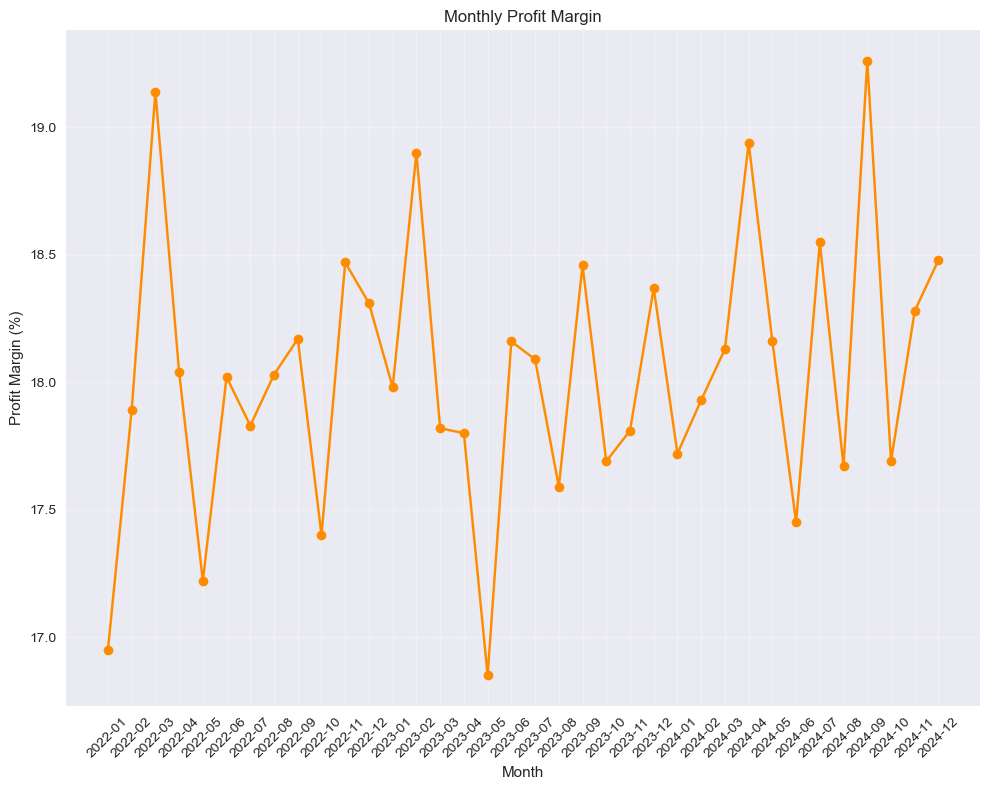

In [33]:
# Profit Margin Chart

plt.figure(figsize=(10, 8))

plt.plot(Monthly_perf["sales_month"].astype(str),Monthly_perf["Profit_margin_pct"],
    marker="o",color="darkorange")

plt.title("Monthly Profit Margin")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Identifying the highest performing month in terms of sales

query = """
SELECT strftime('%Y-%m',Order_date) AS sales_month,
ROUND(SUM(Sales),2) AS Total_sales,
ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y-%m',Order_date)
ORDER BY Total_sales DESC
LIMIT 1;
"""
Best_month_sales = pd.read_sql_query(query,conn)
display(Best_month_sales)

,sales_month,Total_sales,Total_profit,Total_orders
0,2024-05,2605197.57,473176.04,2073


In [35]:
# Best performing month in terms of profit

query = """
SELECT strftime('%Y-%m',Order_date) AS sales_month,
ROUND(SUM(Sales),2) AS Total_sales,
ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y-%m',Order_date)
ORDER BY Total_profit DESC
LIMIT 1;
"""
Best_month_profit = pd.read_sql_query(query,conn)
display(Best_month_profit)

,sales_month,Total_sales,Total_profit,Total_orders
0,2024-05,2605197.57,473176.04,2073


In [36]:
# Best performing month in terms of profit-margin

query = """
SELECT strftime('%Y-%m',Order_date) AS sales_month,
ROUND(SUM(Sales),2) AS Total_sales,
ROUND(SUM(Profit),2) AS Total_profit,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS Profit_margin_pct,
COUNT(DISTINCT Order_id) AS Total_orders
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y-%m',Order_date)
ORDER BY Profit_margin_pct DESC
LIMIT 1;
"""
Best_month_profit_margin = pd.read_sql_query(query,conn)
display(Best_month_profit_margin)

,sales_month,Total_sales,Total_profit,Profit_margin_pct,Total_orders
0,2024-09,1756345.7,338210.02,19.26,1435


In [37]:
# Best performing month in terms of total number of orders

query = """
SELECT strftime('%Y-%m',Order_date) AS sales_month,
ROUND(SUM(Sales),2) AS Total_sales,
ROUND(SUM(Profit),2) AS Total_profit,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS Profit_margin_pct,
COUNT(DISTINCT Order_id) AS Total_orders
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y-%m',Order_date)
ORDER BY Total_orders DESC
LIMIT 1;
"""
Best_month_orders = pd.read_sql_query(query,conn)
display(Best_month_orders)

,sales_month,Total_sales,Total_profit,Profit_margin_pct,Total_orders
0,2024-05,2605197.57,473176.04,18.16,2073


__Findings__
* The best month in terms of sales revenue is May of 2024, with a revenue of approximately ₵2,605,197.57.
* Again, the month of May, 2024, generated the most profit of the 36-month period. The profit value of approximately ₵473,176.04 was the highest of all the other months.
* September, 2024, produced a profit margin of about 19.26%, being the most efficient month.
* A total order of 2073, being the highest order, was recorded for the month of May, 2024.

__Insights__
* The month of May, 2024, being the top-performing month in terms of sales and profits could be attributed to the high volumes of orders made, indicating a high purchasing frequency.



In [38]:
# Analyzing Quarterly performance

query = """
SELECT strftime('%Y',Order_date) ||
'Q' || (CAST((CAST(strftime('%m',Order_date) AS INTEGER) - 1)/3 AS INTEGER) + 1) AS year_quarter,
ROUND(SUM(Sales),2) AS Total_sales, ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders, SUM(Quantity) AS Total_quantity,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS profit_margin_pct
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y',Order_date),CAST((CAST(strftime('%m',Order_date) AS INTEGER)-1)/3 AS INTEGER);
"""
Quarterly_perf = pd.read_sql_query(query,conn)
display(Quarterly_perf)

,year_quarter,Total_sales,Total_profit,Total_orders,Total_quantity,profit_margin_pct
0,2022Q1,3115849.36,561172.08,2556,13446.0,18.01
1,2022Q2,3627069.49,644096.64,3005,15944.0,17.76
2,2022Q3,4102107.31,738762.23,3325,17644.0,18.01
3,2022Q4,4503249.45,813236.35,3653,19290.0,18.06
4,2023Q1,5092173.07,926584.47,4214,22106.0,18.20
5,2023Q2,5707209.56,1004083.66,4587,24157.0,17.59
6,2023Q3,6125374.23,1106350.94,4987,26256.0,18.06
7,2023Q4,6588210.45,1183840.53,5308,28389.0,17.97
8,2024Q1,6709246.30,1203093.44,5489,29010.0,17.93
9,2024Q2,7467804.10,1355323.27,5972,31758.0,18.15


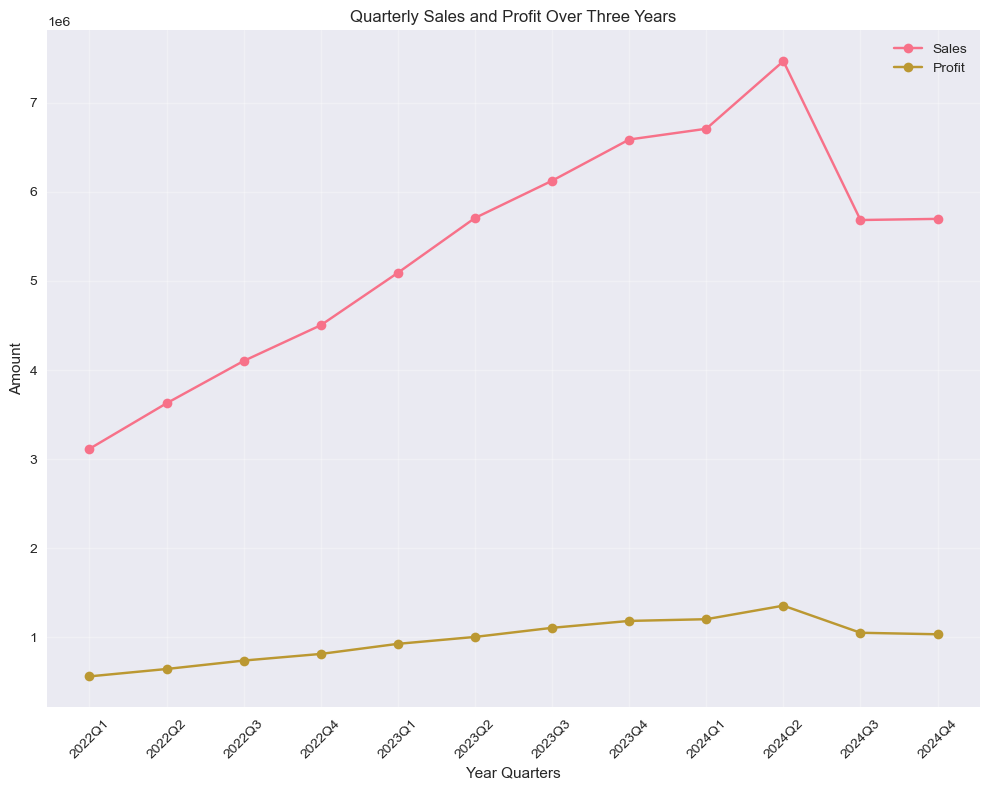

In [39]:
# Quartery Trend Chart To Identify Growth, Declines, Seasonality, and Unusual quarterly Performance.

plt.figure(figsize=(10, 8))

plt.plot(Quarterly_perf["year_quarter"],Quarterly_perf["Total_sales"],marker="o",label="Sales")
plt.plot(Quarterly_perf["year_quarter"],Quarterly_perf["Total_profit"],marker="o",label="Profit")

plt.title("Quarterly Sales and Profit Over Three Years")
plt.xlabel("Year Quarters")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
# Identifying the best performing quarter in terms of sales

query = """
SELECT strftime('%Y',Order_date) ||
'Q' || (CAST((CAST(strftime('%m',Order_date) AS INTEGER) - 1)/3 AS INTEGER) + 1) AS year_quarter,
ROUND(SUM(Sales),2) AS Total_sales, ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders, SUM(Quantity) AS Total_quantity,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS profit_margin_pct
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y',Order_date),CAST((CAST(strftime('%m',Order_date) AS INTEGER)-1)/3 AS INTEGER)
ORDER BY Total_sales DESC
LIMIT 1;
"""
Quarterly_perf_sales = pd.read_sql_query(query,conn)
display(Quarterly_perf_sales)

,year_quarter,Total_sales,Total_profit,Total_orders,Total_quantity,profit_margin_pct
0,2024Q2,7467804.1,1355323.27,5972,31758.0,18.15


In [41]:
# Identifying the best performing quarter in terms of profit

query = """
SELECT strftime('%Y',Order_date) ||
'Q' || (CAST((CAST(strftime('%m',Order_date) AS INTEGER) - 1)/3 AS INTEGER) + 1) AS year_quarter,
ROUND(SUM(Sales),2) AS Total_sales, ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders, SUM(Quantity) AS Total_quantity,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS profit_margin_pct
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y',Order_date),CAST((CAST(strftime('%m',Order_date) AS INTEGER)-1)/3 AS INTEGER)
ORDER BY Total_profit DESC
LIMIT 1;
"""
Quarterly_perf_profit = pd.read_sql_query(query,conn)
display(Quarterly_perf_profit)

,year_quarter,Total_sales,Total_profit,Total_orders,Total_quantity,profit_margin_pct
0,2024Q2,7467804.1,1355323.27,5972,31758.0,18.15


In [42]:
# Identifying the best performing quarter in terms of profit-margin

query = """
SELECT strftime('%Y',Order_date) ||
'Q' || (CAST((CAST(strftime('%m',Order_date) AS INTEGER) - 1)/3 AS INTEGER) + 1) AS year_quarter,
ROUND(SUM(Sales),2) AS Total_sales, ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders, SUM(Quantity) AS Total_quantity,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS profit_margin_pct
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y',Order_date),CAST((CAST(strftime('%m',Order_date) AS INTEGER)-1)/3 AS INTEGER)
ORDER BY profit_margin_pct DESC
LIMIT 1;
"""
Quarterly_perf_profit_margin = pd.read_sql_query(query,conn)
display(Quarterly_perf_profit_margin)

,year_quarter,Total_sales,Total_profit,Total_orders,Total_quantity,profit_margin_pct
0,2024Q3,5684513.54,1050861.75,4620,24618.0,18.49


In [43]:
# Identifying the best performing quarter in terms of quantities sold

query = """
SELECT strftime('%Y',Order_date) ||
'Q' || (CAST((CAST(strftime('%m',Order_date) AS INTEGER) - 1)/3 AS INTEGER) + 1) AS year_quarter,
ROUND(SUM(Sales),2) AS Total_sales, ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders, SUM(Quantity) AS Total_quantity,
ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS profit_margin_pct
FROM retail_sales
WHERE Order_date IS NOT NULL
GROUP BY strftime('%Y',Order_date),CAST((CAST(strftime('%m',Order_date) AS INTEGER)-1)/3 AS INTEGER)
ORDER BY Total_quantity DESC
LIMIT 1;
"""
Quarterly_perf_quantity = pd.read_sql_query(query,conn)
display(Quarterly_perf_quantity)

,year_quarter,Total_sales,Total_profit,Total_orders,Total_quantity,profit_margin_pct
0,2024Q2,7467804.1,1355323.27,5972,31758.0,18.15


__Findings__

* The best-performing quarter in terms of sales revenue generated and profit is the second quarter of 2024 (2024Q2), with the highest total sales of ₵7,467,804 and total profit of ₵1,355,323.

* The third quarter of the year 2024 (2024Q3) had the best profit margin of 18.49%. Hence, the second quarter of 2024 had the best performance in terms of sales, and the third quarter was the most efficient of the quarters.

* The second quarter of 2024 recorded the highest total quantity of 31,758 items sold, as well as the highest total orders of 5,972.

__Insights__

* The best performance of 2024Q2 with regard to sales revenue and profit could be attributed largely to the volume of quantities of items and the frequency of purchases made.
* The third quarter of 2024 (2024Q3) is the most efficient of the quarters, as it converted more sales into profit, as evidently shown by the profit margin.

#### __3. Which customer segment or region contribute the most revenue and profit? And how do revenue,profit and average order value (AOV) differ by customer segment?__ 

#### __Which region contribute the most revenue and profit?__

In [44]:
# Aggregating region by sales revenue and profit

query = """
SELECT Region, ROUND(SUM(Sales),2) AS Total_revenue,ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders,ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS Profit_margin_pct,
SUM(Quantity) AS Total_quantity
FROM retail_sales
GROUP BY Region
ORDER BY Total_revenue DESC;
"""
Region_perf = pd.read_sql_query(query,conn)
display(Region_perf)

,Region,Total_revenue,Total_profit,Total_orders,Profit_margin_pct,Total_quantity
0,North,12949713.85,2361503.01,10438,18.24,55605.0
1,South,12908058.39,2347401.85,10542,18.19,55842.0
2,East,12893875.97,2335371.91,10464,18.11,55577.0
3,West,12861793.00,2305147.22,10472,17.92,55356.0
4,Central,12806791.65,2271909.51,10362,17.74,54773.0


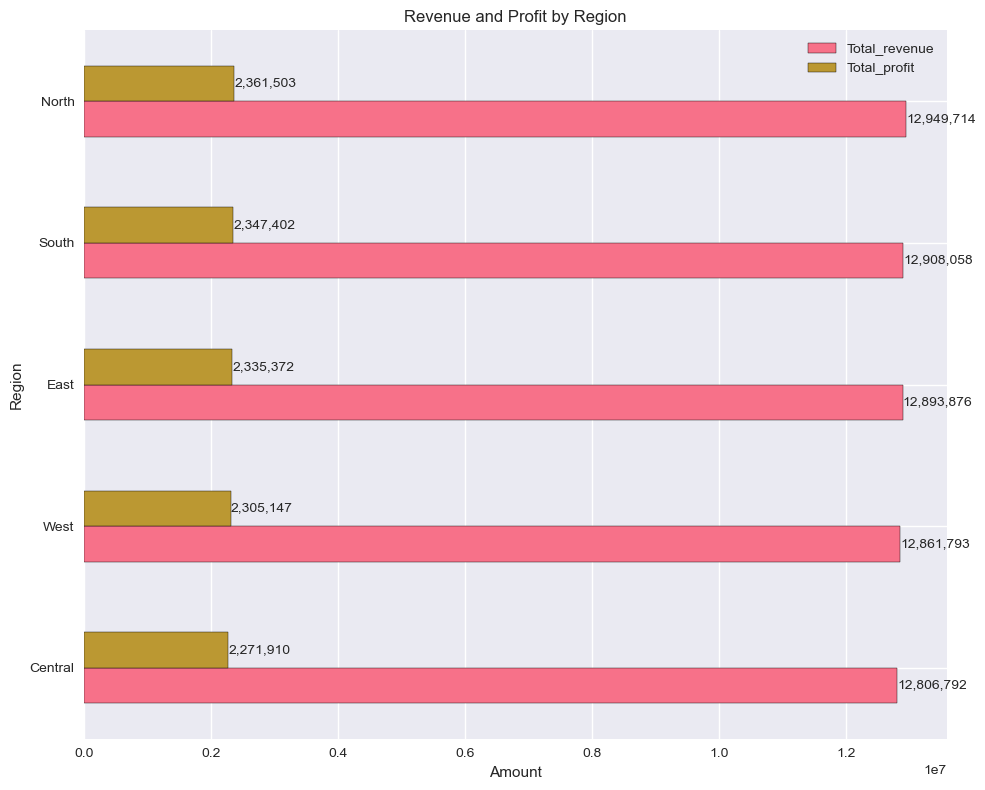

In [45]:
# Bar Chart to visualise sales revenue and profit by regions

ax = Region_perf.sort_values("Total_revenue").plot(kind="barh",x="Region",y=["Total_revenue", "Total_profit"],
                                               figsize = (10,8), edgecolor = 'black')

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.0f}')

plt.title("Revenue and Profit by Region")
plt.xlabel("Amount")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

__Findings__
* The North region generated the highest sales revenue and profit of ₵12,949,713 and ₵2,361,503, respectively.
* The best profit margin of 18.24% was recorded by the North region.
* The South region recorded the highest number of orders made and quantity of items purchased. These numbers are 10,542 for the total number of orders and 55,842 for the total quantity of items.

__Insights__
*  Overall revenue and profit are distributed fairly evenly across all regions, suggesting a balanced business footprint.
* The North region is the most valuable region, having the highest revenue, profit, and profit margin generated.
* The South region is a closed second in terms of value and has the most patronising customer base of all the regions.


#### __Which customer segment contribute the most revenue and profit?__

In [46]:
# Aggregating customer segments by sales revenue and profit

query = """
SELECT Customer_Segment, ROUND(SUM(Sales),2) AS Total_revenue,ROUND(SUM(Profit),2) AS Total_profit,
COUNT(DISTINCT Order_id) AS Total_orders,ROUND(100*SUM(Profit)/NULLIF(SUM(Sales),0),2) AS Profit_margin_pct,
SUM(Quantity) AS Total_quantity
FROM retail_sales
GROUP BY Customer_Segment
ORDER BY Total_revenue DESC;
"""
Customer_seg_perf = pd.read_sql_query(query,conn)
display(Customer_seg_perf)


,Customer_Segment,Total_revenue,Total_profit,Total_orders,Profit_margin_pct,Total_quantity
0,Small Business,21730202.50,3897851.59,17680,17.94,93638.0
1,Corporate,21376500.37,3881951.72,17381,18.16,92002.0
2,Consumer,21313529.99,3841530.19,17217,18.02,91513.0


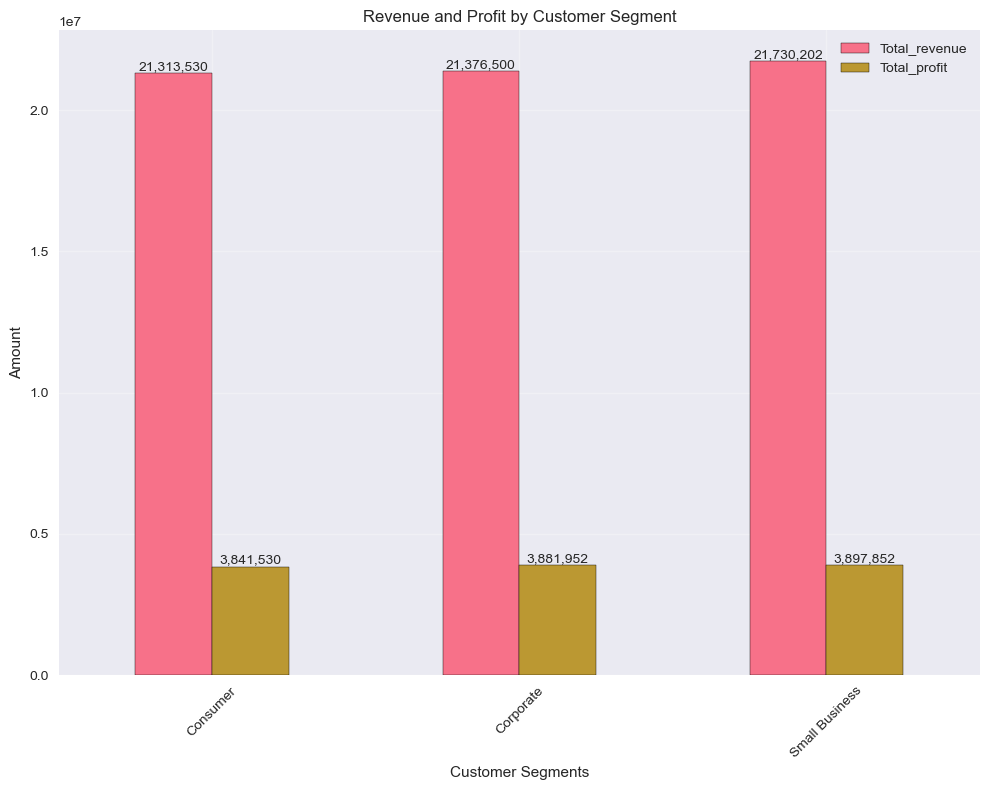

In [47]:
# Bar Chart to visualise sales revenue and profit by regions

ax = Customer_seg_perf.sort_values("Total_revenue").plot(kind="bar",x="Customer_Segment",y=["Total_revenue", "Total_profit"],
                                               figsize = (10,8), edgecolor = 'black')

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.0f}')

plt.title("Revenue and Profit by Customer Segment")
plt.xlabel("Customer Segments")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

__Findings__
* The small business segment made the highest total sales revenue and total profit of ₵21,730,202 and ₵3,897,851, respectively.
* A profit margin of 18.16%, being the highest, was recorded by the corporate group of customers.
* Total orders of 93,638 were made by a small business group of customers, which is the highlighted highest number of orders.

__Insights__
* There is an even distribution of revenue and profit generated across all the customer segments, indicating very balanced business gains across the customer groups.
* The small business segment is the most valuable; having that, the segment generated the most revenue and profit.


#### __And how do revenue,profit and average order value (AOV) differ by customer segment?__

In [48]:
# Calculating the Average order value(AOV) and average profit per order across customer segments

query = """
WITH Order_totals AS (SELECT Order_id,Customer_Segment,SUM(Sales) AS Order_revenue,
SUM(Profit) AS Order_profit
FROM retail_sales
WHERE Order_id IS NOT NULL
GROUP BY Order_id, Customer_Segment)

SELECT Customer_Segment,ROUND(SUM(Order_revenue),2) AS Total_revenue,
ROUND(SUM(Order_profit),2) AS Total_profit,
COUNT(*) AS Total_orders,
ROUND(AVG(Order_revenue),2) AS Average_order_value,
ROUND(AVG(Order_profit),2) AS Average_profit_per_order,
ROUND(100*SUM(Order_profit)/NULLIF(SUM(Order_revenue),0),2) AS profit_margin_pct
FROM Order_totals
GROUP BY Customer_Segment
ORDER BY Average_order_value
DESC;
"""
Customer_seg_AOV = pd.read_sql_query(query,conn)
display(Customer_seg_AOV)

,Customer_Segment,Total_revenue,Total_profit,Total_orders,Average_order_value,Average_profit_per_order,profit_margin_pct
0,Consumer,21313529.99,3841530.19,17217,1237.94,223.12,18.02
1,Corporate,21376500.37,3881951.72,17381,1229.88,223.34,18.16
2,Small Business,21730202.50,3897851.59,17680,1229.08,220.47,17.94


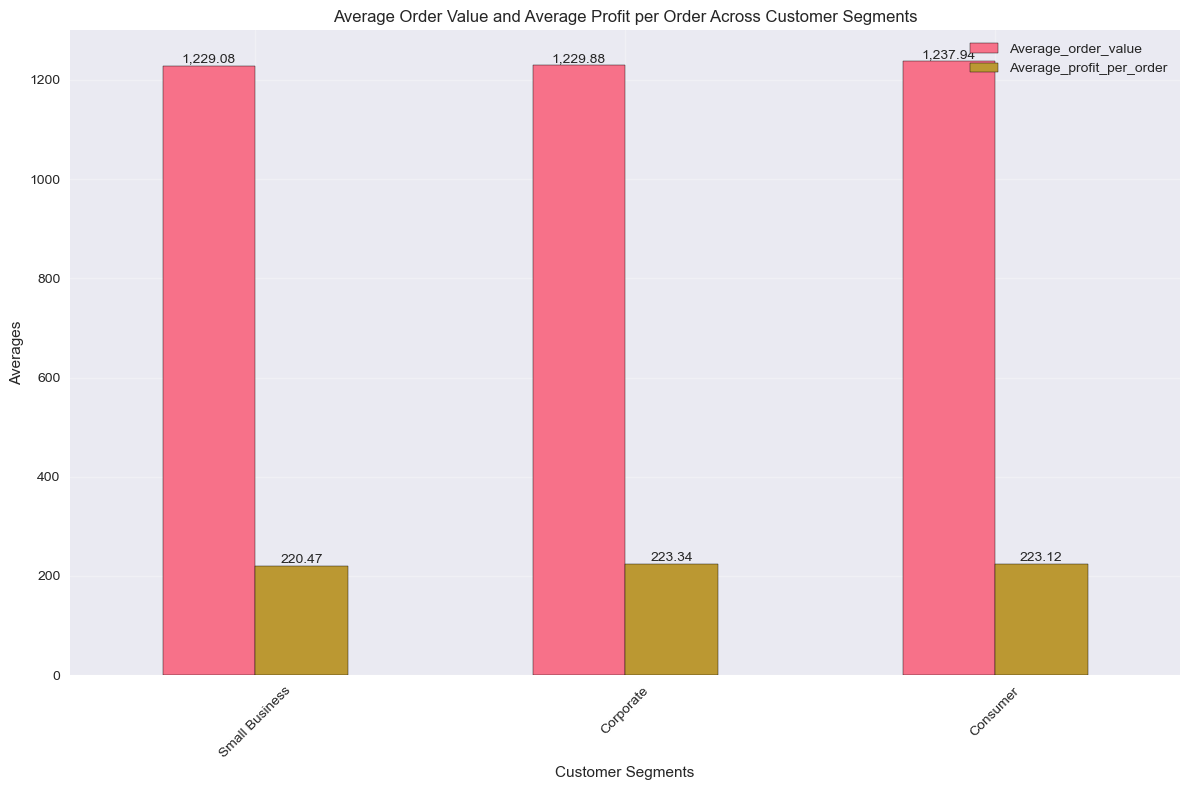

In [49]:
# Bar Chart to visualise AOV and Average profit per order across the customer segments

ax = Customer_seg_AOV.sort_values("Average_order_value").plot(kind="bar",x="Customer_Segment",y=["Average_order_value", "Average_profit_per_order"],
                                               figsize = (12,8), edgecolor = 'black')

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.2f}')

plt.title("Average Order Value and Average Profit per Order Across Customer Segments")
plt.xlabel("Customer Segments")
plt.ylabel("Averages")
plt.xticks(rotation=45)
plt.legend(loc = "upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

__Findings__
* Revenue: Small businesses generate the highest total revenue, contributing ₵ 21,730,202.50.
* Profit: Small businesses also generate the highest total profit at ₵3,897,851.59, although the corporate segment has a higher profit margin of 18.16%.
* Average Order Value: Consumer segment has the highest AOV at ₵1,237.94. 
* Average Profit per Order: Consumer and Corporate segments both have an average profit per order of ₵223.34 and ₵223.12, respectively, which marginally set them apart.    

__Insights__
* There is a fairly even distribution of the average order value and average profit per order across all customer segments, suggesting that customers across these three segments spend approximately the same per order. This also indicates that each order generates a broadly similar amount of profit, on average.
* No customer segment appears to have a substantial advantage in average revenue or profit per order. 

#### __4. How are discounts associated with sales,profit and profit-margin?Which discounts are effective at increasing sales without destroying profitability?__

In [50]:
# ====== Measuring the association ========

# Creating a profit-margin column 

df_clean['Profit_margin'] = df['Profit']/df['Sales']

correlation = df_clean[['Discount','Sales','Profit','Profit_margin']].corr(method = 'spearman')
print(correlation)

               Discount     Sales    Profit  Profit_margin
Discount       1.000000  0.066699 -0.438845      -0.669611
Sales          0.066699  1.000000  0.592133      -0.141801
Profit        -0.438845  0.592133  1.000000       0.600269
Profit_margin -0.669611 -0.141801  0.600269       1.000000


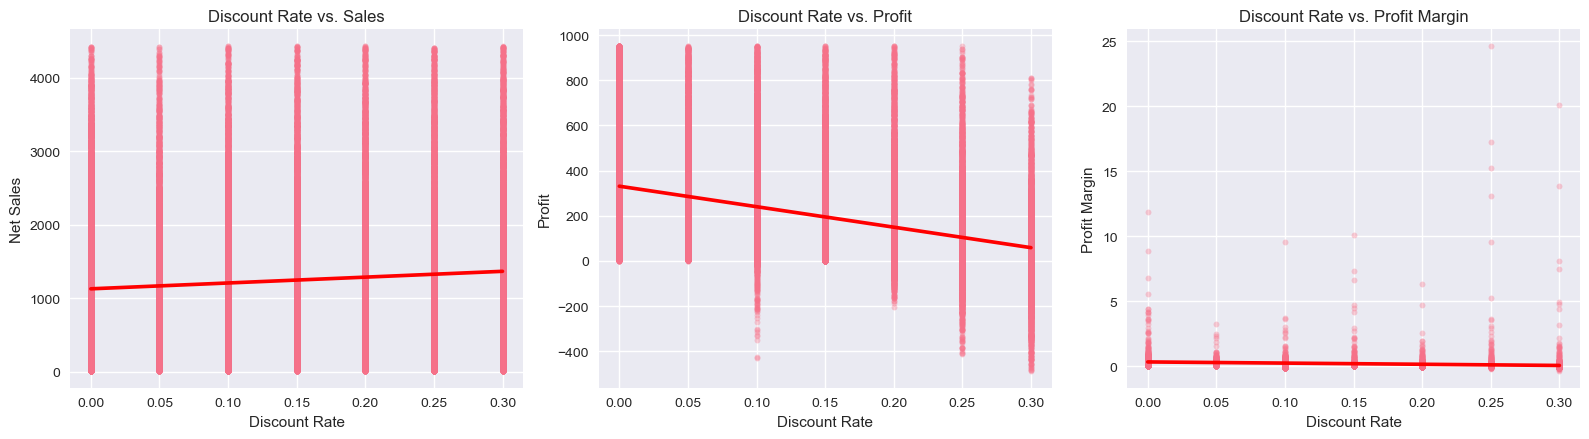

In [51]:
# Visualisation

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.regplot(data=df_clean, x="Discount",y="Sales",ax=axes[0],
    scatter_kws={"alpha": 0.35, "s": 18},line_kws={"color": "red"})
axes[0].set_title("Discount Rate vs. Sales")
axes[0].set_xlabel("Discount Rate")
axes[0].set_ylabel("Net Sales")

sns.regplot(data=df_clean,x="Discount",y="Profit",ax=axes[1],scatter_kws={"alpha": 0.35, "s": 18},
    line_kws={"color": "red"})
axes[1].set_title("Discount Rate vs. Profit")
axes[1].set_xlabel("Discount Rate")
axes[1].set_ylabel("Profit")

sns.regplot(data=df_clean,x="Discount",y="Profit_margin",
    ax=axes[2],scatter_kws={"alpha": 0.35, "s": 18},
    line_kws={"color": "red"})
axes[2].set_title("Discount Rate vs. Profit Margin")
axes[2].set_xlabel("Discount Rate")
axes[2].set_ylabel("Profit Margin")

plt.tight_layout()
plt.show()

In [52]:
# Analyzing performance by discount levels

query = """
SELECT
    Discount,
COUNT(*) AS Total_Transactions,
COUNT(DISTINCT Order_Id) AS Total_Orders,
ROUND(SUM(Sales), 2) AS Total_Sales,
ROUND(AVG(Sales), 2) AS Average_Sales,
ROUND(SUM(Profit), 2) AS Total_Profit,
ROUND(AVG(Profit), 2) AS Average_Profit,
ROUND((SUM(Profit) / NULLIF(SUM(Sales), 0)) * 100,2) AS Profit_Margin

FROM retail_sales
GROUP BY Discount
ORDER BY Discount; 
"""
Discount_levels_perf = pd.read_sql_query(query,conn)
display(Discount_levels_perf)

,Discount,Total_Transactions,Total_Orders,Total_Sales,Average_Sales,Total_Profit,Average_Profit,Profit_Margin
0,0.00,15780,15698,17485284.14,1108.07,5090261.62,322.58,29.11
1,0.05,5395,5373,6326231.19,1172.61,1561242.51,289.39,24.68
2,0.10,7844,7810,9665988.34,1232.28,1927812.77,245.77,19.94
3,0.15,5818,5800,7584398.76,1303.61,1260772.46,216.70,16.62
4,0.20,5858,5833,7642140.37,1304.56,943280.54,161.02,12.34
5,0.25,5976,5946,7853579.38,1314.19,605170.12,101.27,7.71
6,0.30,5922,5901,7862610.68,1327.70,232793.48,39.31,2.96


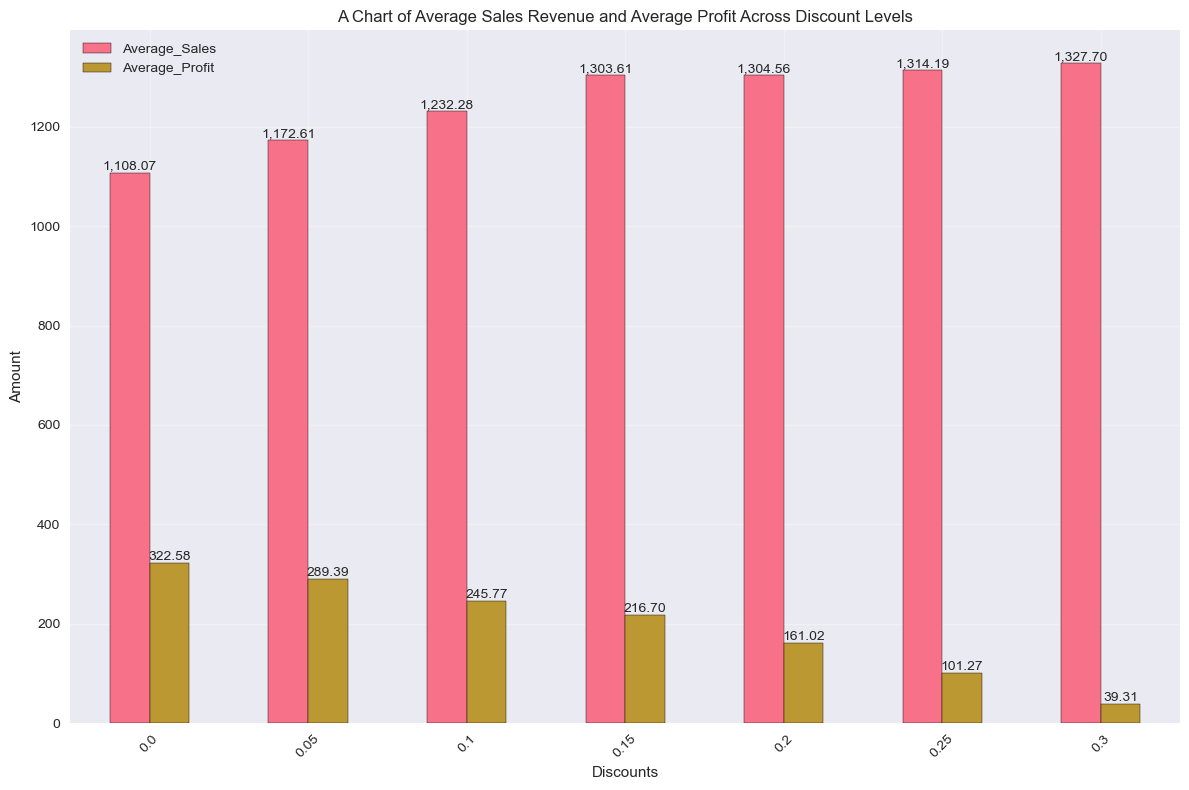

In [53]:
# Visualizing Average Sales revenue and Average Profit across discount levels 

ax = Discount_levels_perf.plot(kind="bar",x="Discount",y=["Average_Sales", "Average_Profit"],
                                               figsize = (12,8), edgecolor = 'black')

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.2f}')

plt.title("A Chart of Average Sales Revenue and Average Profit Across Discount Levels")
plt.xlabel("Discounts")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend(loc = "upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


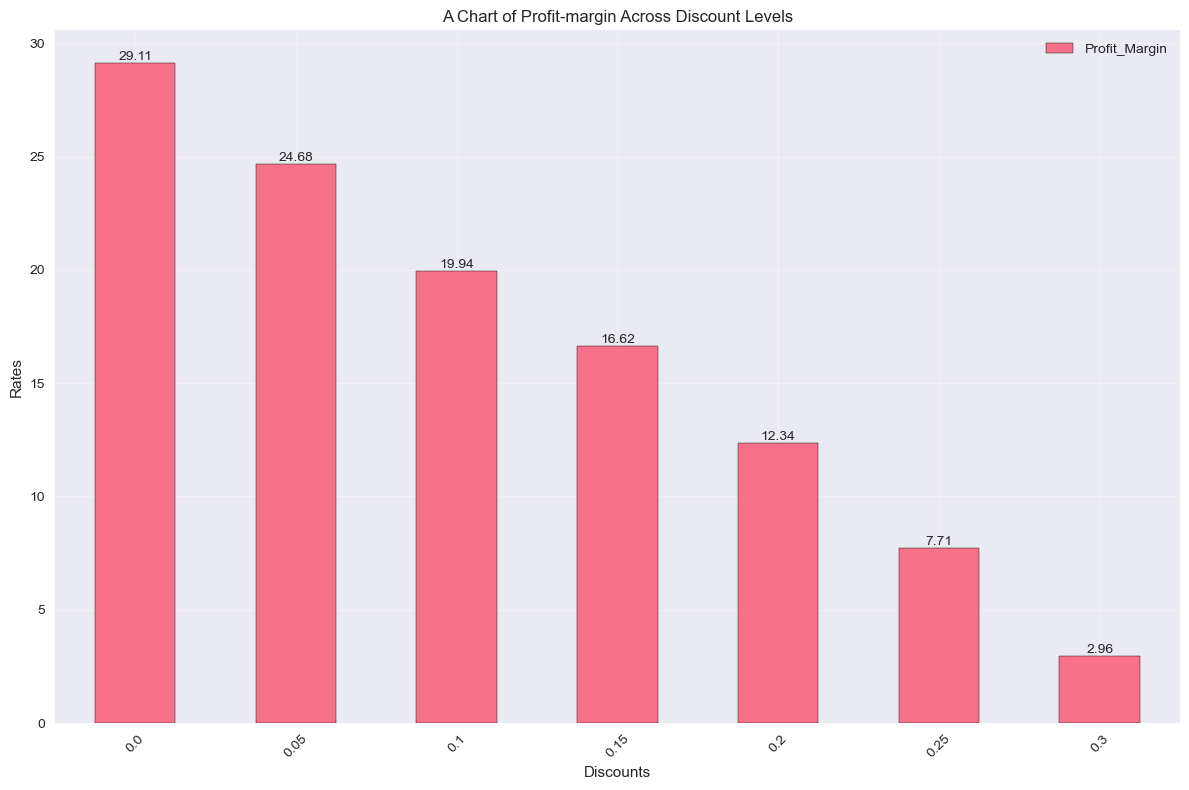

In [54]:
# Visualizing  Profit-margin across discount levels 

ax = Discount_levels_perf.plot(kind="bar",x="Discount",y=["Profit_Margin"],
                                               figsize = (12,8), edgecolor = 'black')

# Data labels
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.2f}')

plt.title("A Chart of Profit-margin Across Discount Levels")
plt.xlabel("Discounts")
plt.ylabel("Rates")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

__Findings__

* Relationship Between Discounts and Sales:
1. A correlation coefficient of 0.0667 between discount and sales indicates a very weak positive linear relationship, as the coefficient is extremely close to zero.
2. Average sales value generally increases as discounts increase.
3. Orders receiving a 30% discount have an average sales value of ₵1,327.70, compared with ₵1,108.07 for orders without discounts, representing approximately a 19.8% increase in average sales value.

* Relationship Between Discount and Profit:
1. A correlation coefficient of -0.4388 indicates a moderate negative linear relationship between discount and profit.
2. Orders without discounts generate the highest average profit of ₵322.58.
3. At a 10% discount, average profit declines to ₵245.77.
4. At a 20% discount, average profit falls to ₵161.02.
5. And at a 30% discount, average profit falls drastically to ₵39.31.

* Relationship Between Discount and Profit Margin;
1. A correlation coefficient of -0.6696 indicates a moderate to strong negative linear relationship between discount and profit margin.
2. Without discounts, the business retains approximately 29.11% of sales revenue as profit.
3. At a 10% discount rate, the profit margin declines at 19.94%.
4. At a 20% discount rate, it falls to 12.34%.
5. At a 30% discount rate, only 2.96% of sales revenue remains as profit.   

__Insights__
* Higher discounts are associated with slightly higher sales values, but the relationship is not strong enough to conclude that discounts independently drive higher sales.
* The average profit drops as discount levels increase, which is indicative of a downward trend. Hence, higher discounts are associated with lower profits.
* There is a consistent decline in profit margin as discounts increase.
* Discounts appear to increase average sales value, but they simultaneously erode profitability.
* A 30% discount leaves the business with very little profit relative to its sales revenue, being the poorest performance with regard to the discount rates.
* The 5% discount level is an attractive discount level for businesses prioritising profitability while encouraging higher sales values.
* The 15% discount level generates higher average sales values while retaining a positive profit margin.


#### __5. How can customers be segmented using Recency,Frequency, and Monetary (RFM) value?And which customers can be classified as "Champions","Loyal","Potential Loyalist","At Risk","Hibernating", or "Lost"?__


In [55]:
# ======= Calculating the RFM metrics ==========

# Recency(R) : A Measure of how recently the customer made a purchase. For this project, 
# the consideration is the number of days after the last purchase,where fewer days signifies a better score.

# Frequency(F) : Measures how often the customer makes purchases, which is indicated by the number of distinct orders,where
# more orders signifies a better score.

# Monetary (M) :A Measure of how much the customer has spent, and it is measure by the total sales revenue generated per customer.

# Calculating one record per customer
query = """
WITH Customer_rfm AS (SELECT Customer_id, MAX(Order_date) AS Last_Purchase,
COUNT(DISTINCT Order_id) AS Frequency,SUM(Sales) AS Monetary
FROM retail_sales
WHERE Customer_id IS NOT NULL
AND Order_id IS NOT NULL
AND Order_date IS NOT NULL
AND Sales IS NOT NULL
GROUP BY Customer_id)

SELECT Customer_id, Last_Purchase,

-- Calculating Recency in days
CAST(julianday(DATE((SELECT MAX(Order_date) FROM retail_sales), '+1 day'))
        - julianday(Last_Purchase)AS INTEGER) AS Recency,
Frequency,Monetary
FROM Customer_rfm;
"""
RFM_metrics = pd.read_sql_query(query, conn)
display(RFM_metrics)

,Customer_id,Last_Purchase,Recency,Frequency,Monetary
0,Cust-00001,2024-12-17 00:00:00,15,9,11296.52
1,Cust-00002,2024-07-21 00:00:00,164,7,8029.78
2,Cust-00003,2024-12-05 00:00:00,27,5,6816.15
3,Cust-00004,2024-08-04 00:00:00,150,11,14217.96
4,Cust-00005,2024-12-03 00:00:00,29,8,13115.66
...,...,...,...,...,...
8963,Cust-08996,2024-11-07 00:00:00,55,10,14295.18
8964,Cust-08997,2024-09-11 00:00:00,112,5,8977.64
8965,Cust-08998,2024-11-12 00:00:00,50,7,6718.56
8966,Cust-08999,2024-10-07 00:00:00,86,7,9599.49


In [56]:
# ======= Calculate RFM Metrics and Scores =======

# For Recency; the fewest days receive a score of 5
# For Frequency and Monetary, the highest score receive a score of 5

# Calculating all 3 metrics and scoring them.

query = """
WITH Customer_rfm AS ( SELECT Customer_id,MAX(DATE(Order_date)) AS Last_Purchase,
COUNT(DISTINCT Order_id) AS Frequency,SUM(Sales) AS Monetary
FROM retail_sales
WHERE Customer_id IS NOT NULL
AND Order_id IS NOT NULL
AND Order_date IS NOT NULL
AND Sales IS NOT NULL
GROUP BY Customer_id),

rfm_days AS (SELECT Customer_id,Last_Purchase,
CAST(julianday(DATE((SELECT MAX(DATE(Order_date))
FROM retail_sales), '+1 day')) - julianday(Last_Purchase)
AS INTEGER) AS Recency,Frequency,Monetary
FROM Customer_rfm),
rfm_scores AS (SELECT*,6 - NTILE(5) OVER (ORDER BY Recency DESC) AS R_score,
NTILE(5) OVER (ORDER BY Frequency ASC) AS F_score,
NTILE(5) OVER (ORDER BY Monetary ASC) AS M_score
FROM rfm_days)

SELECT *, CAST(R_score AS TEXT) || CAST(F_score AS TEXT) ||
CAST(M_score AS TEXT) AS RFM_Score
FROM rfm_scores
ORDER BY R_score DESC, F_score DESC, M_score DESC;
"""

RFM_scores = pd.read_sql_query(query, conn)
display(RFM_scores)

,Customer_id,Last_Purchase,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score
0,Cust-07056,2023-03-11,662,8,11736.38,5,5,5,555
1,Cust-07402,2023-07-30,521,10,12341.44,5,5,5,555
2,Cust-03367,2023-08-16,504,8,10155.91,5,5,5,555
3,Cust-08263,2023-08-21,499,11,10348.84,5,5,5,555
4,Cust-05106,2023-09-14,475,8,15546.06,5,5,5,555
...,...,...,...,...,...,...,...,...,...
8963,Cust-06082,2024-12-30,2,3,3632.58,1,1,1,111
8964,Cust-02834,2024-12-31,1,2,3178.48,1,1,1,111
8965,Cust-00449,2024-12-31,1,4,1255.63,1,1,1,111
8966,Cust-08122,2024-12-31,1,4,2479.19,1,1,1,111


__Understanding and Interpretation of RFM Analysis__

| RFM Metric                  |	           Meaning	                       |   Business Question  |
|-----------------------------|--------------------------------------------|----------------------|
| Recency (R)                 |Number of days since the customer's last purchase | How recently did the customer purchase?|
| Frequency (F)               |Number of distinct orders placed by the customer  | How frequently does the customer purchase?|
| Monetary (M)                |Total amount spent by the customer                | How much revenue does the customer generate? |


* A customer with R_score = 5, F_score = 5, and M_score = 5 obtains an RFM score of 555 which ranks the customer highly on all 3 measures.


In [57]:
# ===== Classification of Customers into the 6 RFM segments (Champions,Loyal,Potential Loyalist,At Risk,Hibernating,and Lost) ====

query = """

WITH Customer_rfm AS (SELECT Customer_id,MAX(Order_date) AS Last_Purchase,
COUNT(DISTINCT Order_id) AS Frequency, SUM(Sales) AS Monetary
FROM retail_sales
WHERE Customer_id IS NOT NULL AND Order_id IS NOT NULL
AND Order_date IS NOT NULL
AND Sales IS NOT NULL
GROUP BY Customer_id),

rfm_days AS (SELECT Customer_id,Last_Purchase,
CAST(julianday(DATE((SELECT MAX(DATE(Order_date))
FROM retail_sales), '+1 day')) - julianday(Last_Purchase)
AS INTEGER) AS Recency,Frequency,Monetary
FROM Customer_rfm),
rfm_scores AS (SELECT*,6 - NTILE(5) OVER (ORDER BY Recency DESC) AS R_score,
NTILE(5) OVER (ORDER BY Frequency ASC) AS F_score,
NTILE(5) OVER (ORDER BY Monetary ASC) AS M_score
FROM rfm_days),
customer_segments AS (SELECT *, CONCAT(R_Score,F_Score,M_Score) AS RFM_Score,
CASE 
WHEN R_Score >= 4 AND F_Score >= 4 AND M_Score >= 4 THEN 'Champions'
WHEN R_Score >= 3 AND F_Score >= 3 THEN 'Loyal'
WHEN R_Score >= 4 AND F_Score <= 3 THEN 'Potential Loyalist'
WHEN R_Score <= 2 AND F_Score >= 3 THEN 'At Risk'
WHEN R_Score = 3  AND F_Score <= 2 THEN 'Hibernating'
ELSE 'Lost'
END AS Customer_Segment FROM rfm_scores)

SELECT Customer_id,Recency,Frequency,Monetary,R_Score,
F_Score,M_Score,RFM_Score,Customer_Segment

FROM customer_segments
ORDER BY 
CASE Customer_Segment 
WHEN 'Champion' THEN 1
WHEN 'Loyal' THEN 2
WHEN 'Potential Loyalist' THEN 3
WHEN 'At Risk' THEN 4
WHEN 'Hibernating' THEN 5
WHEN 'Lost' THEN 6
END,Monetary DESC;
"""
RFM_segment = pd.read_sql_query(query,conn)
display(RFM_segment)

,Customer_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,Customer_Segment
0,Cust-08764,205,11,24582.50,4,5,5,455,Champions
1,Cust-06736,206,11,21374.65,4,5,5,455,Champions
2,Cust-04207,206,9,21307.06,4,5,5,455,Champions
3,Cust-00828,190,12,20900.81,4,5,5,455,Champions
4,Cust-00608,211,14,20614.24,4,5,5,455,Champions
...,...,...,...,...,...,...,...,...,...
8963,Cust-05943,70,3,365.22,2,1,1,211,Lost
8964,Cust-05705,9,1,245.36,1,1,1,111,Lost
8965,Cust-08839,56,1,225.80,2,1,1,211,Lost
8966,Cust-05115,74,1,107.54,2,1,1,211,Lost


In [58]:
# Summary of RFM customer segmentation

query = """
WITH RFM AS ( SELECT Customer_Id,CAST(julianday('2025-01-01') -
            julianday(MAX(Order_Date))
            AS INTEGER) AS Recency,

COUNT(DISTINCT Order_Id) AS Frequency, SUM(Sales) AS Monetary
FROM retail_sales

GROUP BY Customer_Id), RFM_Scores AS ( SELECT *,
6 - NTILE(5) OVER (ORDER BY Recency, Customer_Id) AS R_Score,
NTILE(5) OVER (ORDER BY Frequency, Customer_Id) AS F_Score,
NTILE(5) OVER (ORDER BY Monetary, Customer_Id) AS M_Score
FROM RFM),

Segments AS (SELECT *,CASE
WHEN R_Score >= 4 AND F_Score >= 4 AND M_Score >= 4 THEN 'Champions'
WHEN R_Score >= 3 AND F_Score >= 3 THEN 'Loyal'
WHEN R_Score >= 4 AND F_Score <= 3 THEN 'Potential Loyalist'
WHEN R_Score <= 2 AND F_Score >= 3 THEN 'At Risk'
WHEN R_Score = 3  AND F_Score <= 2 THEN 'Hibernating'
ELSE 'Lost'
END AS Customer_Segment 
FROM RFM_Scores)

SELECT  Customer_Segment, COUNT(*) AS Total_Customers,
ROUND(COUNT(*) * 100.0 /(SELECT COUNT(*) FROM Segments),2) AS Customer_Percentage,
ROUND(AVG(Recency), 2) AS Average_Recency,
ROUND(AVG(Frequency), 2) AS Average_Frequency,
ROUND(AVG(Monetary), 2) AS Average_Monetary,
ROUND(SUM(Monetary), 2) AS Total_Revenue

FROM Segments
GROUP BY Customer_Segment
ORDER BY Total_Customers DESC;
"""
RFM_summary = pd.read_sql_query(query,conn)
display(RFM_summary)

,Customer_Segment,Total_Customers,Customer_Percentage,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
0,Loyal,2375,26.48,86.26,6.83,7835.15,18608492.29
1,Lost,2011,22.42,387.45,3.37,4200.13,8446459.27
2,At Risk,1575,17.56,289.09,6.81,8345.12,13143560.49
3,Champions,1430,15.95,41.88,8.67,11599.10,16586720.03
4,Potential Loyalist,964,10.75,45.57,3.96,4911.01,4734210.89
5,Hibernating,613,6.84,130.53,3.80,4732.12,2900789.89


In [59]:
# Saving RFM summary data
RFM_summary.to_csv('RFM_summary_dataset.csv',index = False)


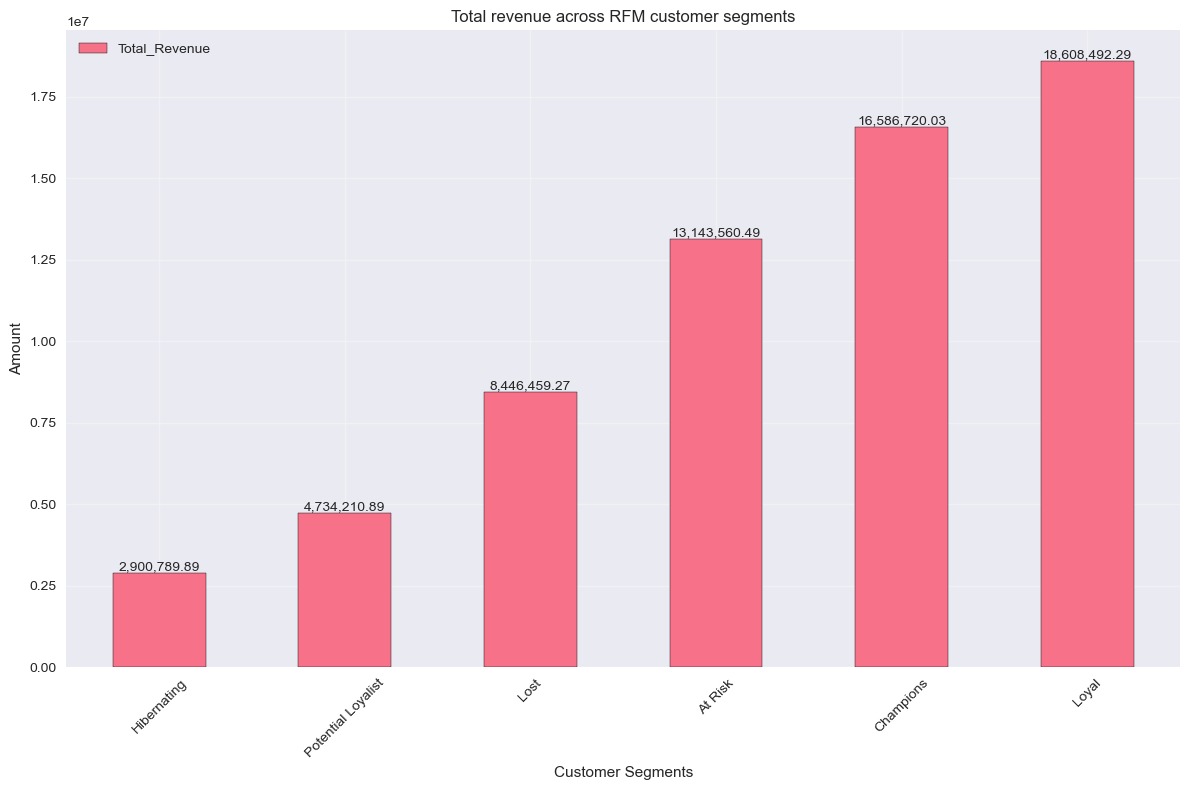

In [60]:
# Visualisation of Total revenue across the RFM customer segment

ax = RFM_summary.sort_values("Total_Revenue").plot(kind="bar",x="Customer_Segment",y=["Total_Revenue"],
                                               figsize = (12,8), edgecolor = 'black')

# Data labels 
for container in ax.containers:
    ax.bar_label(container, fmt = '{:,.2f}')

plt.title("Total revenue across RFM customer segments")
plt.xlabel("Customer Segments")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


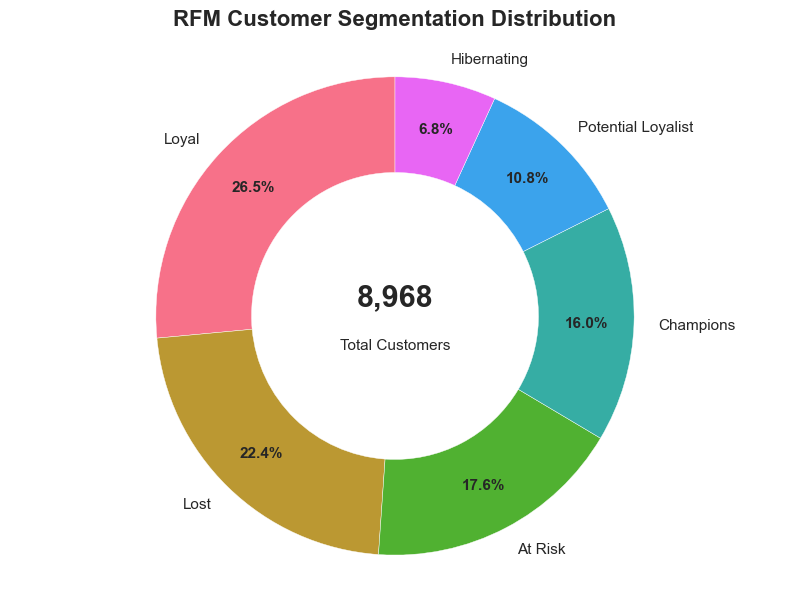

In [61]:
# Visualizing the proportion of customers belonging to each RFM customer segment

# Creating donut chart
fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(RFM_summary['Customer_Percentage'],
labels=RFM_summary['Customer_Segment'],
    autopct='%1.1f%%',startangle=90,pctdistance=0.80,
    wedgeprops=dict(width=0.40,edgecolor='white'),textprops=dict(fontsize=11))

# Adding total number of customer  to the centre of the chart
total_customers = RFM_summary['Total_Customers'].sum()

ax.text(0, 0.08,f'{total_customers:,}',ha='center',
    va='center',fontsize=22,fontweight='bold')

ax.text(0, -0.12,'Total Customers',ha='center',
    va='center',fontsize=11)

# Format percentage labels
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')

# Chart title

ax.set_title('RFM Customer Segmentation Distribution',
    fontsize=16,fontweight='bold',pad=20)
ax.axis('equal')
plt.tight_layout()
plt.show()

__Findings and interpretation of results__

1. Loyal Customers : This customer segment makes up the largest of the RFM customer segments. 26.5% of the overall customer base belong to this segment where purchases are frequent and maintain a reasonable engagement with the business.As a result, this segment generated the highest sales revenue of ₵18,608,492.29

2. Lost Customers: These customers make up 22.43% of the customer base and have characteristics of not making recent purchases and generally have a relatively low purchasing frequency. This segment generated one of the lowest revenue (₵8,446,459.27) of the lot. 

3. At Risk Customers: This group of customers previously patronised the business and demonstated relatively high purchasing frequency but since not made any recent purchases. This group is 17.57% of the customer base and generated a revenue of ₵13,143,560.49, which is the third highest.

4. Champions: This group is the most valuable as they purchased recently, purchase frequently, and spend relatively more.They make up 15.95% of the customer base and generated a revenue of ₵16,586,720.03, being the second highest generated.

5. Potential Loyalists: 10.75% of the customer base is made up of customers in this group, with a characteristic of making made recent purchases but not established a high purchasing frequency. This group generated a revenue of ₵4,734,210.89 which is one of the lowest.

6. Hibernating Customers:This segment makes 6.82% of the customer base and the least. These are customers with relatively low purchasing frequency.

__Insights__
* Though Loyal segment of customers generates the highest total revenue,Champion segment generates the highest average monetary value per customer.
* The number of customers that fell in the Risk category could potentially represent a retention challenge since they have a relatively high historical purchasing frequency.

## __Interactive Dashboard__

### __Sales Performance Dashboard__

**Purpose:**
To provide management with a high level overview of sales, profitability, product performance, customer segments and regional performance.

**Business Questions:**
1. Which product categories generate the most revenue and profit?

2. Which months or quarters perform best?

3. Which customer segment or region contributes the most revenue and profit? And how do revenue, profit, and average order value (AOV) differ by customer segment?

**Description:**
This dashboard is made of 6 different visualisations with 6 filters. It compares revenue contributions and profits by product categories as well as regional contributions. It also makes a comparison of revenue proportion contributions by customer segments and analyses monthly sales trends year-over-year and on a quarterly basis. The KPIs tracked by this dashboard are total revenue, total profit, profit margin, total orders, total customers, and average order value. Users can filter by region, year, month, quarter, product category, and customer segment.

[Open the interactive dashboard on Tableau public](https://public.tableau.com/app/profile/leslie.odoi/viz/RetailSalesPerformanceandCustomerValueAnalysisSalesPerformance/SalesPerformancedashboard)


### __Discount and Profitability Dashboard__

**Purpose:**
Investigate whether discounts are associated with higher sales and whether the additional sales justify the reduction in profitability.

**Business Question:**
How are discounts associated with sales, profit, and profit margin? Which discounts are effective at increasing sales without destroying profitability?

**Description:**
This dashboard looks at the sales revenue and profits, as well as profit margin across the 5 discount levels, to establish what relationships exist between discounts versus sales, discounts versus profits, and discounts versus profit margin. This dashboard also provides insights on discount effectiveness across product categories as well as the overall discount effectiveness with regard to sales and profitability. The navigation of this dashboard is made possible by the region, product category, discounts, and customer segment filters.

[Open the interactive dashboard here on Tableau public](https://public.tableau.com/app/profile/leslie.odoi/viz/RetailSalesPerformanceandCustomerValueAnalysisDiscountandProfitability/DiscountandProfitabilityAnalysis)


### __Customer Segmentation and RFM Analysis Dashboard__

**Purpose:**
Identify valuable customers, understand purchasing behaviour and identify customers who may require retention interventions.

**Business Question:**
How can customers be segmented using Recency, Frequency, and Monetary (RFM) value? And which customers can be classified as "Champions", "Loyal", "Potential Loyalists", "At Risk", "Hibernating", or "Lost"?

**Description:**
This dashboard tracks the average monetary value of each RFM segment, as well as the revenue contribution of each segment. It also looks into the constituent or proportion of each RFM segment relative to the entire number of customers. Average frequency and recency across the 6 segments are also captured and navigated by the use of the RFM segment filter. The KPIs captured include total revenue, total profit, loss-making orders (orders that resulted in loses), profit margin, and average.

[Open the interactive dashboard here on Tableau public](https://public.tableau.com/app/profile/leslie.odoi/viz/RetailSalesPerformanceandCustomerValueAnalysisCustomerSegmentationandRFMAnalysis/RFM_Dashboard)









## __Recommendation__

Based on the findings of the analysis, the following actions are recommended to improve the performance of the business:

1. __Improvement of sales and profitability:__
* Pricing strategies of office supply products should be investigated by management to ascertain the cause of generating higher sales revenue than home and kitchen supplies but not profit.
* Management should investigate why sales, profit, and frequency of purchasing were so high in the month of May, 2024, to see how best the performances of other months could be boosted by applying the same principle as in May, 2024.
*  Management should investigate what drives strong performance in the second quarter (Q2). Is it as a result of promotions, product mix, or seasonality?
* Strategies that worked in the second quarter (Q2) should be implemented in weaker quarters.
* Priority should be placed on high performing product categories and regions while investigating the factors contributing to weaker performances elsewhere.

2. __Optimisation of discount strategies:__
* Discount levels should be evaluated against sales growth, profit and profit margins to ensure that promotional activities align with a long term sustainable profitability.
* 5%–10% discounts should be prioritise, as these levels of discounts provide a reasonable balance between higher average sales and profitability.
*  15% discounts should be used selectively and applied to products with sufficient gross margins or where additional sales volume justifies the reduction in profitability.
* There should be a review of discount rate strategy between 20% and 30%, as they are associated with substantial reductions in profit margins.

3. __Strengthening of customer retention:__
* The North and South regions should receive priority when it comes to customer retention and loyalty campaigns since they are the largest contributors of sales revenue and profit.
* Customers in the small business segment should be considered as strong candidates for V.I.P., loyalty, and retention programmes since they are the largest contributors of revenue and profit.
* Champion and Loyal segment customers should be treated as a priority in customer retention strategies, as they both combine to generate a substantial revenue contribution to the business.
* The Risk and Hibernating segment of customers should be investigated to find appropriate customer retention strategies because losing those customers could weaken future revenue performance. 

4. __Increment of customer lifetime value:__
* Insights from the RFM analysis should be used to identify opportunities for personalised marketing campaigns targetting the various RFM segments.
*  Broadly consistent pricing and promotional strategies should be applied across all customer segments, while still accounting for customer needs.

5. __Monitoring of business performance:__
* Constant monitoring of the business performance, as in monitoring of KPIs such as revenue, profit margins, average order value, customer retention and segment level revenue contribution, should be established through interactive dashboards.

## __Conclusion__

This analysis provided an indepth assessment of the company's retail sales performance and customer purchasing behaviour. By leveraging SQL for the analysis, Python for visualisation, and Tableau for dashboard reports, the study examined key business performance indicators, identified revenue and profit drivers, and evaluated customer value through RFM segmentation. 
Overall, this project demonstrates how the integration of data analytics, business intelligence and customer segmentation can be employed to draw insight from business data to aid in business decision making.

The insights from the analysis can aid management make more informed decisions regarding sales optimisation, profitability management, promotional strategies and customer relationship management. Hence improving operational efficiency, stronger customer relationships and sustainable business growth.